# Shor Code

## Initialisation

In [ ]:
!pip install qiskit

import qiskit

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit import transpile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 2.3 MB/s eta 0:00:00


Initialising variables for each 'block' (a block is a set of 3 qubits that will seperately undergo a 3 qubit repetition code for bit-flips). Then also initialising the ancilla qubits for the parity check for the phase-flip.

In [ ]:
b1_qr = QuantumRegister(3,'XQ1')
b1_ar = QuantumRegister(2,'XA1')
b1_cr = ClassicalRegister(2, 'XC1')

b2_qr = QuantumRegister(3,'XQ2')
b2_ar = QuantumRegister(2, 'XA2')
b2_cr = ClassicalRegister(2,'XC2')

b3_qr = QuantumRegister(3,'XQ3')
b3_ar = QuantumRegister(2, 'XA3')
b3_cr = ClassicalRegister(2,'XC3')

phase_ar = QuantumRegister(2, 'ZA')
phase_cr = ClassicalRegister(2,'ZC')

final_cr = ClassicalRegister(1, 'final_output')

Creating the circuit and then grouping together the different register types for easier reference

In [ ]:
qc = QuantumCircuit(b1_qr, b1_cr, b1_ar,
                    b2_qr, b2_cr, b2_ar,
                    b3_qr, b3_cr, b3_ar,
                    phase_cr, phase_ar,
                    final_cr)

start_qubits = [0,5,10] #First qubit of each block
qubit_regs = [b1_qr, b2_qr, b3_qr]
classical_regs = [b1_cr, b2_cr, b3_cr]
ancilla_regs = [b1_ar, b2_ar, b3_ar]

blocks = [[b1_qr, b1_cr, b1_ar],
          [b2_qr, b2_cr, b2_ar],
          [b3_qr, b3_cr, b3_ar]]


## Preparing the State Vector


Prepares the inital qubit (qubit 0) into a given state, so Shor code error correction can be tested.

In [ ]:
!pip install numpy

import numpy as np
from qiskit.quantum_info import Statevector

In [ ]:
def prepare_statevector():
    #Prepare the initial qubit to any arbitary state
    qc.x(0)
    qc.h(0)
    qc.x(0)
    qc.ry(np.pi/4, 0)

## Encoding
Encoding the logical qubit into 3 physical qubits and then encoding these qubits into 3 further physical qubits. The first encoding is set up for the phase flip, and the second encoding is set up for the 3 seperate bit flips.

In [ ]:
def Encoding():
#encoding for phase flip
    qc.cx(b1_qr[0], b2_qr[0])
    qc.cx(b1_qr[0], b3_qr[0])

    #applying hadamard for phase flip
    for reg in qubit_regs:
        qc.h(reg[0])

    for qr in qubit_regs:
        qc.cx(qr[0], qr[1])
        qc.cx(qr[0], qr[2])

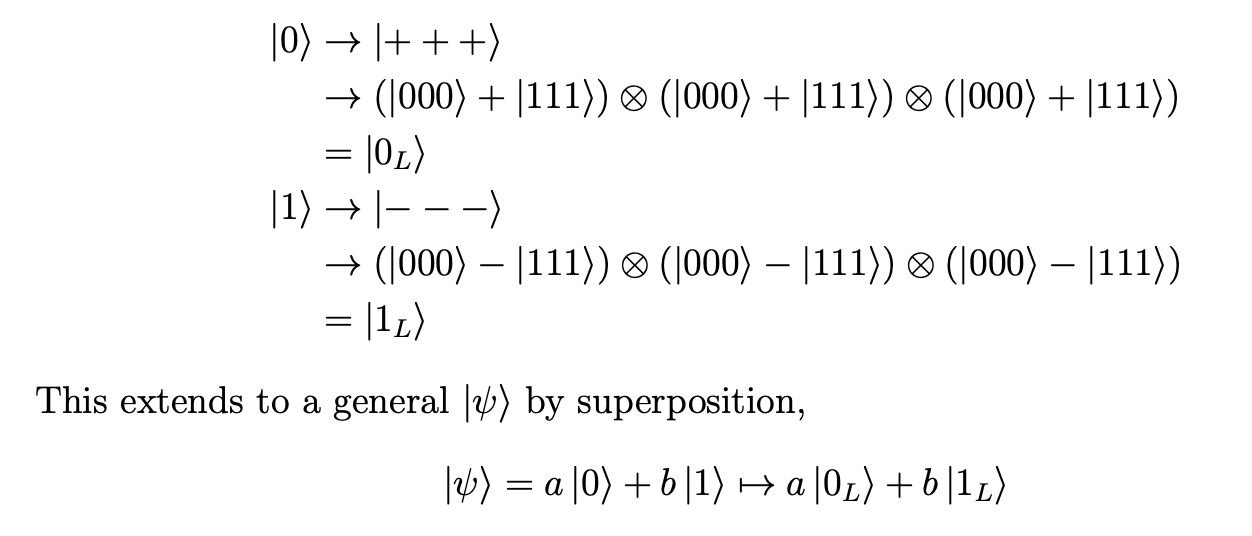

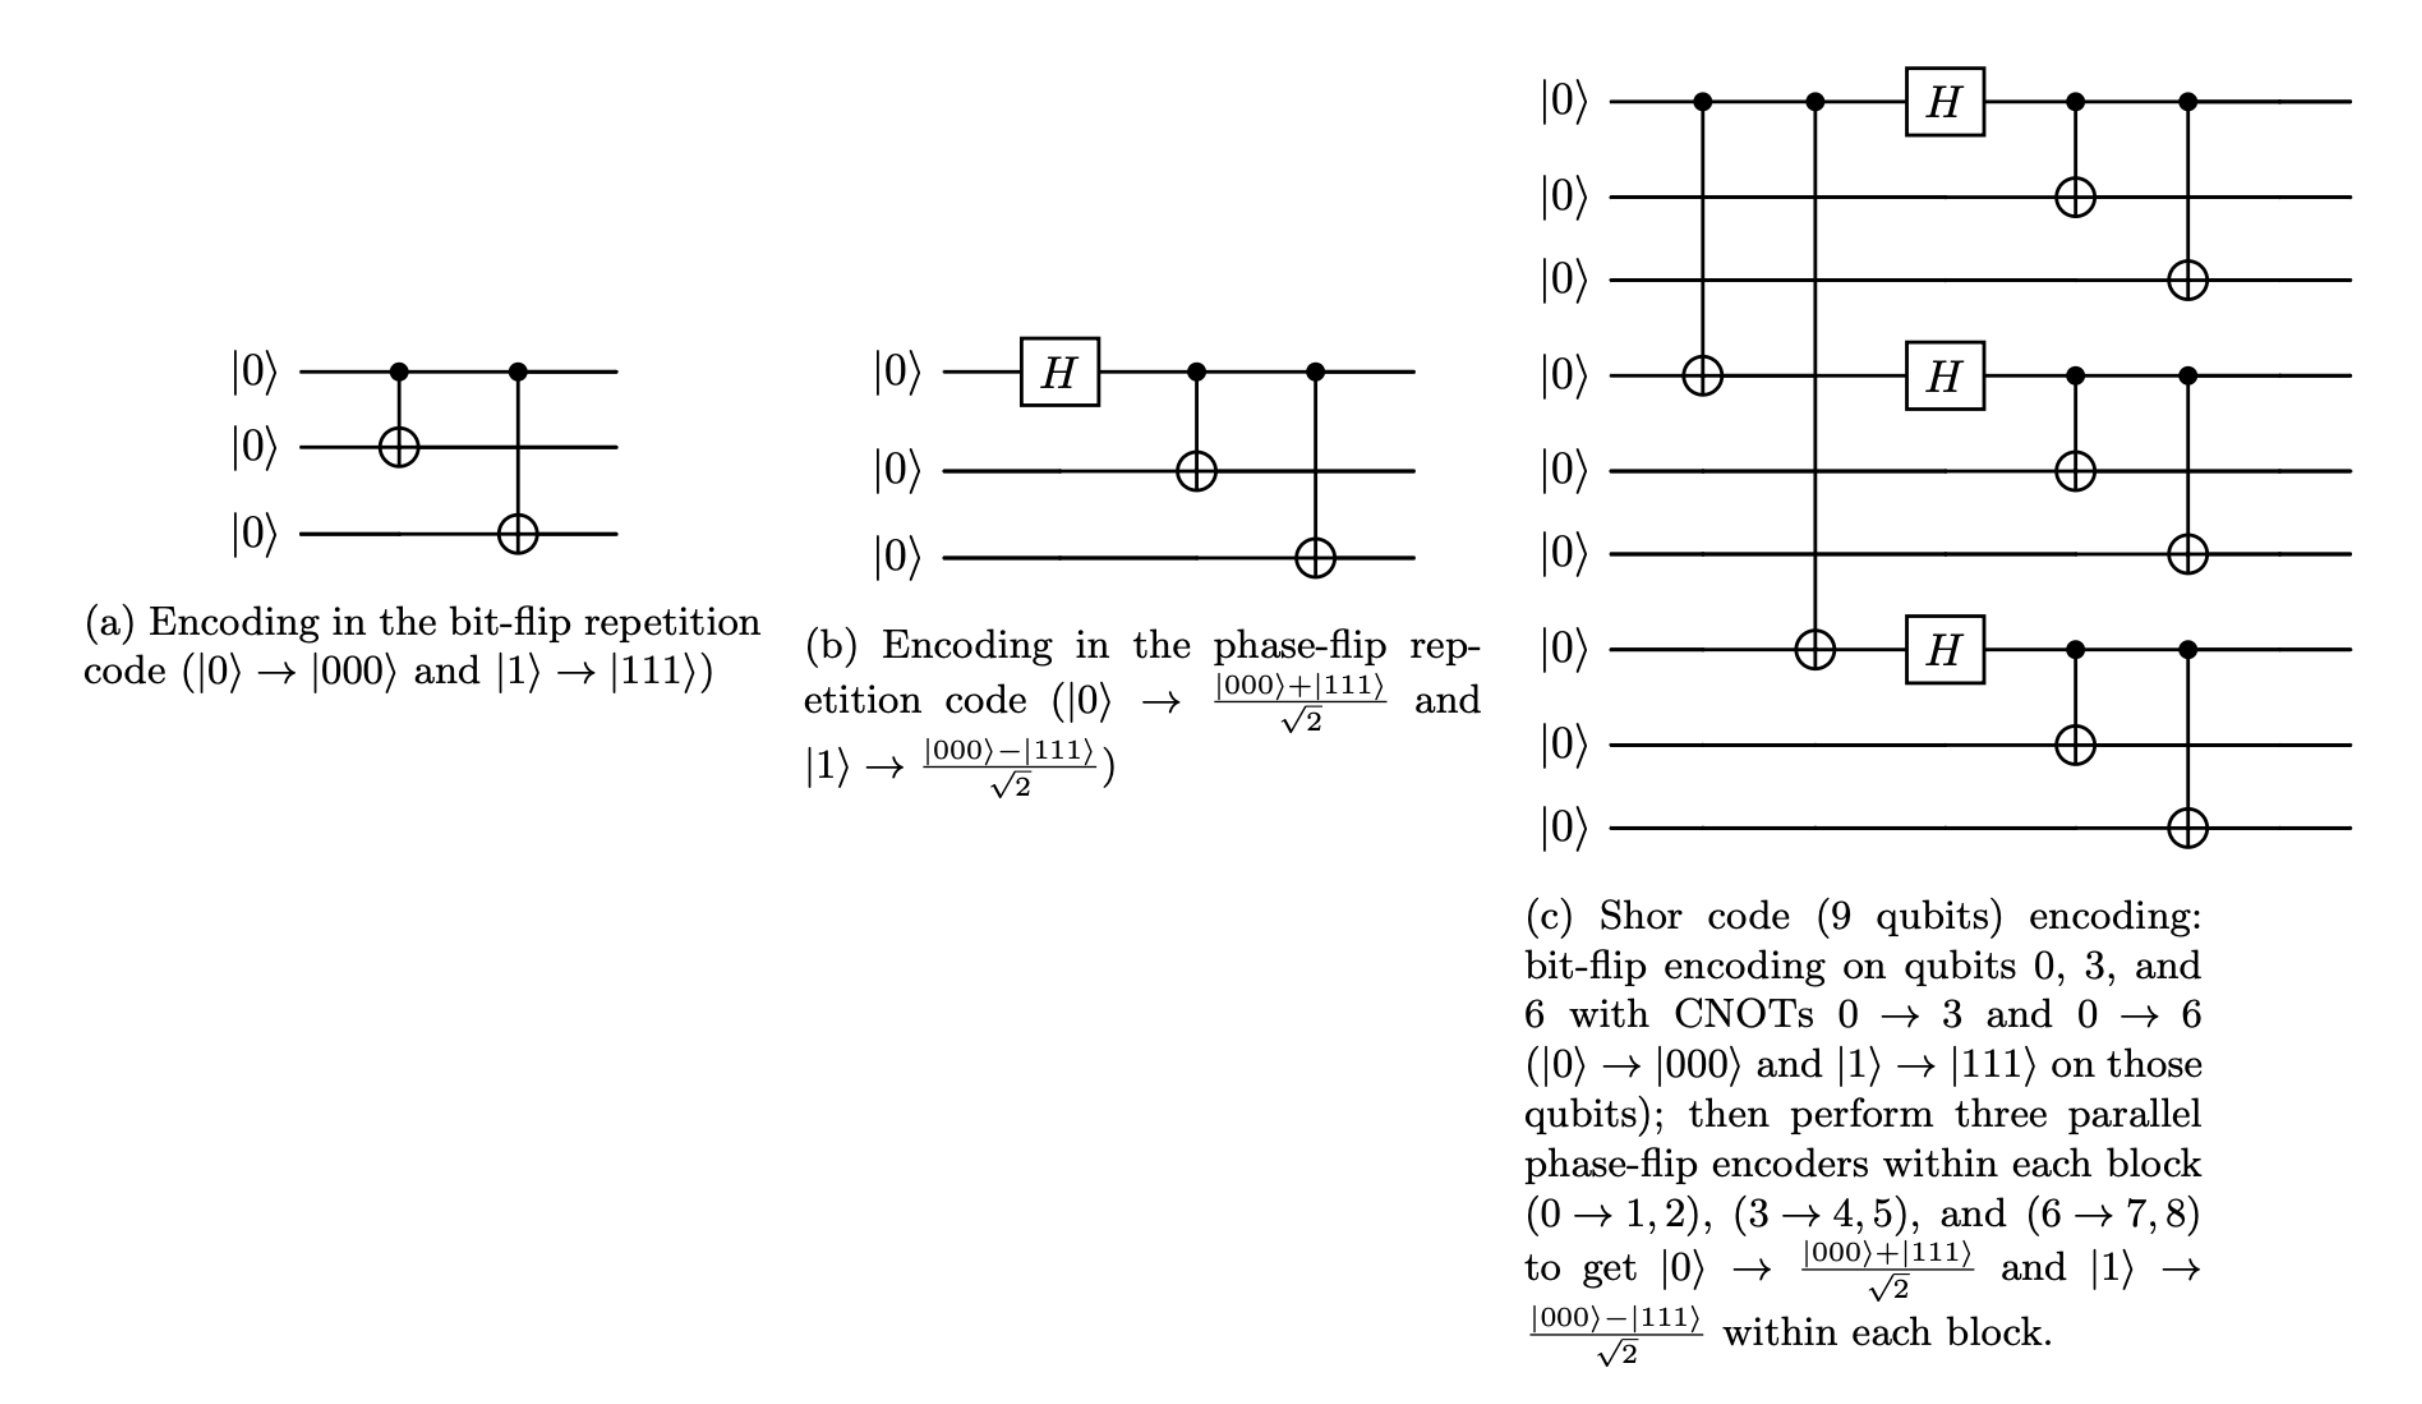

## Error Generation
Inserting an error for testing to ensure all errors are corrected

In [ ]:
def Error(self, x_pos = None, z_pos = None):
        if x_pos and x_pos >= 0 and x_pos <= 9:
            self.qc.x(self.qc.qubits[x_pos])
        elif z_pos and z_pos >= 0 and z_pos <= 9:
            self.qc.z(self.qc.qubits[x_pos])


##Error Correction

### Correcting bit flips
The parity check between the three qubits occurs comparing the first pair of qubits, and then the second pair, with the result being stored as the syndrome measurement.
The parity check is done by addition mod 2 using the cnot gates to the ancilla qubits.
We assume there is at most one bit flip.
We have CNOTS of the first and second qubit onto the first ancilla qubit, and CNOTS of the second and third qubit onto the second ancilla qubit. Using this allows to define a syndrome that tells us whether a bit flip occurred and on which qubit.

e.g. If the syndrome is 01 this means there was a bit flip on the third qubit.
This is because as the parity check is 0 for the first and second qubit, they both must not have any error. As the parity check for the second and third qubit is 1, there must be an error here. So we know there is an error on the third qubit.

The ancilla qubits are then measured and an if test occurs to correct the bit flip based off of the syndrome measurement.
*This only works if one bit-flip has occured in the block of qubits, otherwise it will fail to correct the error.

In [ ]:
#Bit flip circuit construction
def BitFlip(qr, cr, ar):
    #syndrome measurement and parity check

    #parity check (if r0 != r1, cr1 = 0, if r1 != r2, cr1 = 1)
    qc.cx(qr[0], ar[0])
    qc.cx(qr[1], ar[0])
    qc.cx(qr[1], ar[1])
    qc.cx(qr[2], ar[1])

    qc.measure(ar, cr)

    with qc.if_test((cr, 1)):
        qc.x(qr[2])
    with qc.if_test((cr, 2)):
        qc.x(qr[0])
    with qc.if_test((cr, 3)):
        qc.x(qr[1])


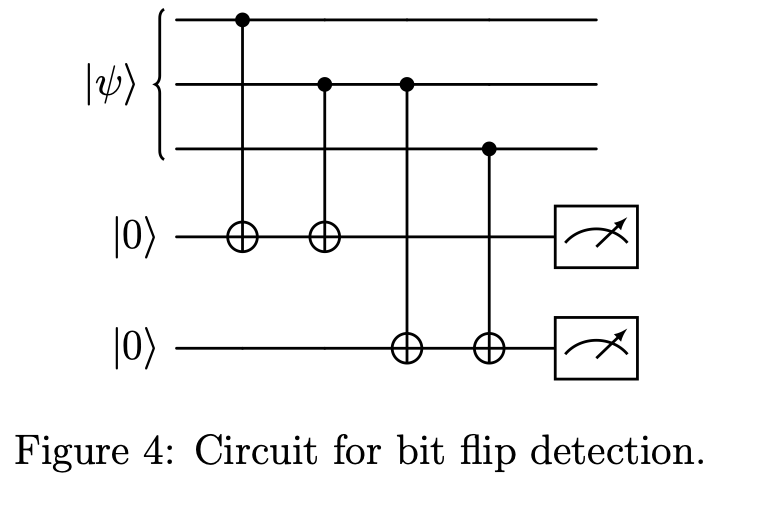

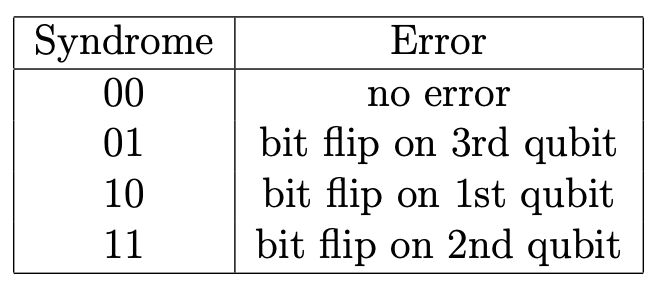

### Correcting Phase Flips
Applying a hadamard gate to all qubits that were encoded for the bit flip correction to go from |000> to |+++> and |111> to |--->. This is because HZH = X. Then the parity check is performed. As Z|+> = |-> and Z|-> = |+>, the parity check is now equivalent to parity check used with the bit flip.
Then based off the syndrome, a Z gate is applied to the corresponding block to correct any phase flip errors. And then a Hadamard Gate is reapplied to return to the 0 and 1 states.

In [ ]:
def PhaseFlip():
    for qr in qubit_regs:
        for qubit in qr:
            qc.h(qubit)

    #block 1  - 3
    for block_clbit in range(3):
        for phase_anclbit in range(2):
            qc.cx(b1_qr[block_clbit], phase_ar[phase_anclbit])

    for block_clbit in range(3):
        qc.cx(b2_qr[block_clbit], phase_ar[0])

    for block_clbit in range(3):
        qc.cx(b3_qr[block_clbit], phase_ar[0])

    qc.measure(phase_ar, phase_cr)
    with qc.if_test((phase_cr, 1)):
        qc.z(b3_qr[0])
    with qc.if_test((phase_cr, 2)):
        qc.z(b1_qr[0])
    with qc.if_test((phase_cr, 3)):
        qc.z(b2_qr[0])

    for qr in qubit_regs:
        for qubit in qr:
            qc.h(qubit)

## Decoding
In order to return to one singular qubit at the end of the error checking the bit encoding is reversed, then the phase encoding, then the block entanglement.

In [ ]:
def Decoding():
     # undo bit-flip encoding
    for qr in qubit_regs:
        qc.cx(qr[0], qr[2])
        qc.cx(qr[0], qr[1])

    # undo phase encoding
    for start in start_qubits:
        qc.h(qc.qubits[start])

    # undo block entanglement
    qc.cx(b1_qr[0], b3_qr[0])
    qc.cx(b1_qr[0], b2_qr[0])

## Sampling and Running
The circuit is then ran on a simulator 1024 times recording the final measurement each time. The probabilities of measuring 0 and 1, based on the number of shots for the corresponding measurement, are then outputted based on this sample.

In [ ]:
!pip install qiskit_aer
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSampler

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 30.3 MB/s eta 0:00:00


In [ ]:
def Sampling(self):
        sampler = AerSampler()
        sampling_job = sampler.run([self.qc], shots=64)
        result = sampling_job.result()

        counts = result[0].data.final_output.get_counts()
        return counts

Execute combines all the above functions into a singular function to be called. This is so when we make a main file with both the shor and surface codes to demo error correction we do not have to copy all these seperate functions.

In [ ]:
!pip install matplotlib
import matplotlib.pyplot as plt

In [ ]:
def Execute(self, x_pos = None, z_pos = None):
        self.Encoding()
        self.Error(x_pos, z_pos)

        for i in range(3):
            self.BitFlip(self.qubit_regs[i], self.classical_regs[i], self.ancilla_regs[i])

        self.PhaseFlip()
        self.Decoding()

        self.qc.measure(self.qc.qubits[0], self.final_cr)

        #fig = (self.qc.draw(output = "mpl", fold = -1))
        #plt.show()

        output = self.Sampling()

        print(f'Probability of 1: {output.get("1", 0)/64 * 100:.2f}%')
        print(f'Probability of 0: {output.get("0", 0)/64 * 100:.2f}%')

# Surface Code

##Initialisation

In [ ]:
from unittest import case

from numpy.linalg import qr
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit import transpile
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
import matplotlib.patches as mpatches
import networkx as nx

##Surface Code Graph Class

In [ ]:
class Surface_Code_Graph:
##make the graph of the surface code, with the data qubits and the ancilla qubits in their respective positions
    def __init__(self, d):
        if d < 2:
            raise ValueError("d must be greater than or equal to 2")
        self.d = d
        self.data_q, self.z_anc, self.x_anc, self.qr = self.layout(d)
        self.define_stabilisers()

        self.circuit = QuantumCircuit(self.qr)

    def layout(self,d):
        #store each qubit as its coordinates in the grid
        #key is the coordinate, value is the qubit
        data_q = {}
        z_anc = {}
        x_anc = {}

        coords = []
        for i in range(2*d-1):
            for j in range(2*d-1):
                coords.append((i,j))

        #make a register for each qubit
        qr = QuantumRegister(len(coords),'q')
        qubit_coords = {}

        #goes thru each coordinate pair and assigns a qubit that is in the qr register
        for idx, (i,j) in enumerate(coords):
            qubit_coords[(i,j)] = qr[idx]

    #assigning the different types of qubits their respective spots
        for (i,j), qubit in qubit_coords.items():
            if (i+j) % 2 == 0:
                data_q[(i,j)] = qubit
            elif i % 2 == 0:
                z_anc[(i,j)] = qubit
            else:
                x_anc[(i,j)] = qubit

        return data_q, z_anc, x_anc, qr

    def define_stabilisers(self):
        # This defines the X and Z stabilisers for the lattice as dictionaries (is NOT ACTUALLY implementing them/ measuring)
        # Each dictionary maps a coordinate of the X stabilise/X measuremnt ancilla to the 4 adjacent data qubits

        self.x_stabilisers = {}
        self.z_stabilisers = {}

        #Each X stabiliser and Z stabiliser respectively correspond to a X or Z measurement qubit

        #Connecting the X measurement qubit with a given X stabiliser

        for ancilla in self.x_anc:
            i, j = ancilla
            neighbours = [(i-1, j), (i+1, j), (i, j-1), (i, j+1)]

        # Only include neighbors that are data qubits
            data_neighbours = []
            for n in neighbours:
                if n in self.data_q:
                    data_neighbours.append(n)

            if data_neighbours:  # Only add if there are valid neighbors
                self.x_stabilisers[ancilla] = data_neighbours

    #Connecting the Z measurement qubit with a given Z stabiliser

        for ancilla in self.z_anc:
            i, j = ancilla
            neighbours = [(i-1, j), (i+1, j), (i, j-1), (i, j+1)]

            # Only include neighbors that are data qubits
            data_neighbours = []
            for n in neighbours:
                if n in self.data_q:
                    data_neighbours.append(n)

            if data_neighbours:  # Only add if there are valid neighbors
                self.z_stabilisers[ancilla] = data_neighbours

    def _add_elements(self, shape, colour, label, qubit_dict, ax):
        match shape:
            case 'circle':
                for coord in qubit_dict:
                    i, j = coord
                    element = Circle((j,i), 0.3, color = colour, ec = 'white', linewidth = 2)
                    ax.add_patch(element)
                    ax.text(j, i, label, ha = 'center', va = 'center', fontweight = 'bold', fontsize = 10)
            case 'square':
                for coord in qubit_dict:
                    i, j = coord
                    element = Rectangle((j-0.3/2,i-0.3/2), 0.3, 0.3, color = colour, ec = 'black', linewidth = 2)
                    ax.add_patch(element)
                    ax.text(j, i, label, ha = 'center', va = 'center', fontweight = 'bold', fontsize = 10)
            case 'connection':
                for coord, qubits in qubit_dict:
                    i, j = coord
                    for qi, qj in qubits:
                        ax.plot([j, qj], [i, qi], color =colour, linestyle = label, alpha=0.7, linewidth = 2)

    def visualise_layout(self):
        fig, ax = plt.subplots(1, 1, figsize=(10,8))

        size = 2 * self.d - 1 #dimensions of the grid

        #draw data qubits
        self._add_elements('connection', 'grey', '--', self.x_stabilisers.items(),ax)
        self._add_elements('connection', 'grey', '-', self.z_stabilisers.items(),ax)
        self._add_elements('circle', 'navy', 'D', self.data_q,ax)
        self._add_elements('square', 'yellowgreen', 'X', self.x_anc,ax)
        self._add_elements('square', 'lightgreen', 'Z', self.z_anc,ax)


        ax.set_xlim(-0.5, size-0.5)
        ax.set_ylim(-0.5, size-0.5)
        ax.set_aspect('equal')
        ax.invert_yaxis()
        plt.tight_layout()
        plt.show()

## Syndrome Extraction Class

In [ ]:
class SyndromeExtraction(Surface_Code_Graph):
    """
    Implement syndrome extraction circuits.
    Create separate circuits for X and Z syndrome extraction.

    Returns:
    --------
    - X syndrome extraction circuit
    - Z syndrome extraction circuit
    - Circuit depth and total operations for both circuits
    - No. of parallel CNOT layers
    """

    def __init__(self, distance):
        super().__init__(distance)
        self.x_measure_dict = {}
        self.z_measure_dict = {}


    ef create_x_syndrome_circuit(self):
        """
        Create X syndrome extraction circuit.
        The syndrome extraction circuit is optimized to
        implement conflict-free CNOT gates.
        """

        self.circuit = QuantumCircuit(self.qr, self.classical_x)

        for qubit_obj in self.x_anc.values():
            self.circuit.reset(qubit_obj)



        for qubit_obj in self.data_q.values():
            self.circuit.h(qubit_obj)


        self.organize_x_cnots()

        for qubit_obj in self.data_q.values():
            self.circuit.h(qubit_obj)




        # Measurement of X measure qubits
        x_measure_dict = {}
        i = 0
        for measure_pos in self.x_anc:
            measure_qubit = self.x_anc[measure_pos]

            self.circuit.measure(measure_qubit,self.classical_x[i])
            x_measure_dict[measure_pos] = '0'
            i += 1



        #Returning the measurement of the ancilla qubits in the X syndrome extraction circuit as a BIT STRING
        sim = AerSimulator()
        result = sim.run(transpile(self.circuit, sim), shots=1024).result()

        counts = result.get_counts()
        print("Counts from X syndrome extraction:", counts)
        bitstring = next(iter(counts))

        bitstring = bitstring[::-1]  # Reverse to read left-to-right matching index 0
        print("Bitstring from X syndrome extraction:", bitstring)
        x_measure_dict = {}
        i = 0
        for measure_pos in self.x_anc:

            x_measure_dict[measure_pos] = bitstring[i]
            i += 1

        self.x_measure_dict = x_measure_dict
        return self.x_measure_dict







    def create_z_syndrome_circuit(self):
        """
        Create Z syndrome extraction circuit.
        The syndrome extraction circuit is optimized to
        implement conflict-free CNOT gates.

        """

        self.circuit = QuantumCircuit(self.qr, self.classical_z)
        for qubit_obj in self.z_anc.values():
            self.circuit.reset(qubit_obj)
        self.organize_z_cnots()



        # Measurement of Z measure qubits
        z_measure_dict = {}

        i = 0
        for measure_pos in self.z_anc:
            measure_qubit = self.z_anc[measure_pos]


            self.circuit.measure(measure_qubit, self.classical_z[i])
            z_measure_dict[measure_pos] = '0'
            i += 1

        #Returning the measurement of the ancilla qubits in the X syndrome extraction circuit as a BIT STRING
        sim = AerSimulator()
        result = sim.run(transpile(self.circuit, sim), shots=1024).result()

        counts = result.get_counts()
        print("Counts from Z syndrome extraction:", counts)
        bitstring = next(iter(counts))


        bitstring = bitstring[::-1]  # Reverse the bitstring to match the order of qubits in the circuit
        print("Bitstring from Z syndrome extraction:", bitstring)
        z_measure_dict = {}
        i = 0
        for measure_pos in self.z_anc:
            z_measure_dict[measure_pos] = bitstring[i]
            i += 1
        self.z_measure_dict = z_measure_dict

        return self.z_measure_dict






    def organize_x_cnots(self):
        """
        Organize CNOT gates of the x-stabilizer measurement into conflict-free layers.
        """
        layers = []
        remaining_cnots = []

        # Collect all CNOT operations for X stabilizers
        for measure_pos, data_positions in self.x_stabilisers.items():
            measure_qubit = self.x_anc[measure_pos]
            for data_pos in data_positions:
                data_qubit = self.data_q[data_pos]
                remaining_cnots.append([measure_qubit, data_qubit])
        #Storing a list of all the CNOTs that need to be implemented for the X stabilisers in a list called remaining_cnots

        # avoid conflicts
        while remaining_cnots:
            current_layer = []
            used_qubits = set()

            i = 0
            while i < len(remaining_cnots):
                cnot = remaining_cnots[i]
                control, target = cnot

                # Check if any qubit in this CNOT is already used in current layer
                if control not in used_qubits and target not in used_qubits:
                    current_layer.append(cnot)
                    used_qubits.add(control)
                    used_qubits.add(target)
                    remaining_cnots.pop(i)
                else:
                    i += 1

            if current_layer:
                layers.append(current_layer)

        #The above has created a list of lists called layers, where each inner list contains CNOTs that can be applied in parallel without conflict. This used a greedy algorithm to iteratively build layers of CNOTs, ensuring that no qubit is involved in multiple operations within the same layer.

        #Applying the CNOTs in each layer to the circuit

        for layer in layers:
            for pair in layer:
                control, target = pair
                self.circuit.cx(control, target)


    def organize_z_cnots(self):
        """
        Organize CNOT gates of the z-stabiliser measurement into conflict-free layers.
        """
        layers = []
        remaining_cnots = []

        # Collect all CNOT operations for Z stabilizers
        for measure_pos, data_positions in self.z_stabilisers.items():
            measure_qubit = self.z_anc[measure_pos]
            for data_pos in data_positions:
                data_qubit = self.data_q[data_pos]
                remaining_cnots.append([data_qubit, measure_qubit])

        # avoid conflicts
        while remaining_cnots:
            current_layer = []
            used_qubits = set()

            i = 0
            while i < len(remaining_cnots):
                cnot = remaining_cnots[i]
                control, target = cnot

                # Check if any qubit in this CNOT is already used in current layer
                if control not in used_qubits and target not in used_qubits:
                    current_layer.append(cnot)
                    used_qubits.add(control)
                    used_qubits.add(target)
                    remaining_cnots.pop(i)
                else:
                    i += 1

            if current_layer:
                layers.append(current_layer)

        #The above has created a list of lists called layers, where each inner list contains CNOTs that can be applied in parallel without conflict. This used a greedy algorithm to iteratively build layers of CNOTs, ensuring that no qubit is involved in multiple operations within the same layer.
        #Applying the CNOTs in each layer to the circuit

        for layer in layers:
            for pair in layer:
                control, target = pair
                self.circuit.cx(control, target)

    def draw_circuit(self):
        """
        Draw the circuit for the syndrome extraction.
        """
        fig = self.circuit.draw(output='mpl')

        plt.show()


#Demo

In [ ]:
from Surface_Code import Error_Correction
from Shor_Code import ShorCode

#run surface code -> inputs inouts as parameters
d = 4
surface = Error_Correction(d)
surface.Execute(x_errors= [(3,1), (1,3), (4,4)], z_errors=[(4,4)], visual= True)

#run shor code -> inputs as parameters
shor = ShorCode()
shor.Execute(5,8)

###Surafce Code UI


In [ ]:
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>Surface Code — Error Correction Lab</title>
<style>
  :root{
    --ink:#0d1b2a;
    --paper:#eef1f6;
    --panel:#16273d;
    --panel-line:#2a3f5c;
    --lattice:#9fb3c8;
    --data:#3b5bdb;
    --xanc:#4a9c6d;
    --zanc:#7ec98f;
    --xerr:#ef2d7e;
    --zerr:#22d3ee;
    --yerr:#a855c9;
    --triggered:#a855c9;
    --amber:#e0a83e;
    --mono: "IBM Plex Mono", "SFMono-Regular", Consolas, monospace;
    --serif: "Fraunces", "Iowan Old Style", Georgia, serif;
  }
  *{box-sizing:border-box;}
  body{
    margin:0;
    font-family:var(--mono);
    background:var(--ink);
    color:#dfe7f2;
    min-height:100vh;
  }
  header{
    padding:28px 36px 18px;
    border-bottom:1px solid var(--panel-line);
    display:flex;
    align-items:baseline;
    justify-content:space-between;
    flex-wrap:wrap;
    gap:12px;
  }
  header h1{
    font-family:var(--serif);
    font-weight:600;
    font-size:1.7rem;
    margin:0;
    letter-spacing:0.2px;
    color:#fff;
  }
  header .tag{
    font-size:0.72rem;
    letter-spacing:0.14em;
    text-transform:uppercase;
    color:var(--amber);
  }
  .stage-label{
    font-size:0.72rem;
    letter-spacing:0.12em;
    text-transform:uppercase;
    color:#8ea3bd;
  }
  .layout{
    display:grid;
    grid-template-columns: 1fr 340px;
    gap:0;
    min-height:calc(100vh - 90px);
  }
  .canvas-wrap{
    padding:28px 20px 40px;
    display:flex;
    flex-direction:column;
    align-items:center;
    gap:18px;
  }
  #stage-title{
    font-family:var(--serif);
    font-size:1.15rem;
    color:#fff;
  }
  .board-frame{
    background:var(--panel);
    border:1px solid var(--panel-line);
    border-radius:4px;
    padding:18px;
  }
  #board{
    display:flex;
    gap:22px;
    flex-wrap:wrap;
    justify-content:center;
    align-items:flex-start;
  }
  .panel-block{
    display:flex;
    flex-direction:column;
    align-items:center;
    gap:8px;
  }
  .panel-title{
    font-size:0.68rem;
    letter-spacing:0.12em;
    text-transform:uppercase;
    color:#8ea3bd;
  }
  svg{ display:block; }
  .qubit-hit{ cursor:pointer; }
  .qubit-hit:hover circle.base{ stroke:#fff; stroke-width:2.5; }
  .controls-row{
    display:flex;
    gap:10px;
    flex-wrap:wrap;
    justify-content:center;
  }
  button{
    font-family:var(--mono);
    font-size:0.78rem;
    letter-spacing:0.03em;
    text-transform:uppercase;
    background:transparent;
    color:#dfe7f2;
    border:1px solid var(--panel-line);
    padding:10px 16px;
    border-radius:3px;
    cursor:pointer;
    transition:background 0.15s, border-color 0.15s;
  }
  button:hover{ border-color:var(--amber); color:#fff; }
  button.primary{ background:var(--amber); color:#1a1200; border-color:var(--amber); font-weight:600;}
  button.primary:hover{ filter:brightness(1.08); }
  button:disabled{ opacity:0.35; cursor:not-allowed; }
  button.primary:disabled{ background:#5c5230; border-color:#5c5230; color:#8a8060;}

  .legend{
    display:flex;
    flex-wrap:wrap;
    gap:14px 22px;
    justify-content:center;
    font-size:0.72rem;
    color:#aebdd1;
    max-width:640px;
  }
  .legend-item{ display:flex; align-items:center; gap:6px; }
  .swatch{ width:12px; height:12px; border-radius:50%; display:inline-block; border:2px solid #000; }
  .swatch.sq{ border-radius:2px; }

  aside{
    background:#0a1420;
    border-left:1px solid var(--panel-line);
    padding:28px 26px 40px;
    overflow-y:auto;
  }
  aside h2{
    font-family:var(--serif);
    font-size:1.0rem;
    color:#fff;
    margin:0 0 4px;
  }
  aside .step-eyebrow{
    font-size:0.68rem;
    letter-spacing:0.14em;
    text-transform:uppercase;
    color:var(--amber);
    margin-bottom:2px;
  }
  aside p{
    font-size:0.82rem;
    line-height:1.55;
    color:#b8c4d6;
    margin:0 0 16px;
  }
  aside .divider{
    border:none;
    border-top:1px solid var(--panel-line);
    margin:20px 0;
  }
  .field{
    margin-bottom:18px;
  }
  .field label{
    display:block;
    font-size:0.7rem;
    letter-spacing:0.1em;
    text-transform:uppercase;
    color:#8ea3bd;
    margin-bottom:6px;
  }
  .dselect{
    display:flex;
    gap:6px;
  }
  .dselect button{
    flex:1;
    padding:8px 0;
  }
  .dselect button.active{
    background:var(--data);
    border-color:var(--data);
    color:#fff;
  }
  .err-list{
    font-size:0.76rem;
    color:#cdd8e8;
  }
  .err-list div{
    display:flex;
    justify-content:space-between;
    padding:3px 0;
    border-bottom:1px dotted #22344c;
  }
  .err-list .tag-x{ color:var(--xerr); }
  .err-list .tag-z{ color:var(--zerr); }
  .err-list .tag-y{ color:var(--yerr); }
  .empty-note{ color:#5c6d84; font-style:italic; font-size:0.78rem; }

  pre.codeblock{
    background:#050b12;
    border:1px solid var(--panel-line);
    border-radius:3px;
    padding:14px;
    font-size:0.72rem;
    line-height:1.6;
    color:#8fe3a0;
    overflow-x:auto;
    white-space:pre-wrap;
    word-break:break-word;
  }
  .copy-btn{
    width:100%;
    margin-top:8px;
  }
  .status-banner{
    font-size:0.76rem;
    padding:10px 12px;
    border-radius:3px;
    border:1px solid var(--panel-line);
    margin-bottom:16px;
    min-height:1.2em;
  }
  .status-banner.correcting{ color:var(--amber); border-color:var(--amber); }
  .status-banner.done{ color:var(--zanc); border-color:var(--zanc); }
  .status-banner.errs{ color:var(--xerr); border-color:var(--xerr); }

  .correction-log{
    width:100%;
    max-width:820px;
    background:var(--panel);
    border:1px solid var(--panel-line);
    border-radius:4px;
    padding:14px 18px;
    font-size:0.78rem;
    line-height:1.6;
    color:#cdd8e8;
  }
  .correction-log h3{
    font-family:var(--serif);
    font-size:0.9rem;
    color:#fff;
    margin:0 0 10px;
  }
  .log-entry{
    border-bottom:1px dotted var(--panel-line);
    padding:10px 0;
  }
  .log-entry:last-child{ border-bottom:none; }
  .log-entry .log-title{
    font-weight:700;
    margin-bottom:4px;
  }
  .log-entry .log-title.x{ color:var(--xerr); }
  .log-entry .log-title.z{ color:var(--zerr); }
  .log-entry ul{
    margin:4px 0 0 18px;
    padding:0;
  }
  .log-entry li{ margin-bottom:2px; }

  ::-webkit-scrollbar{width:8px;}
  ::-webkit-scrollbar-thumb{background:var(--panel-line); border-radius:4px;}

  @media (max-width: 880px){
    .layout{ grid-template-columns: 1fr; }
    aside{ border-left:none; border-top:1px solid var(--panel-line); }
  }
</style>
</head>
<body>

<header>
  <h1>Surface Code — Error Correction Lab</h1>
  <span class="tag">powered by Surface_Code.py · click to inject errors</span>
</header>

<div class="layout">

  <div class="canvas-wrap">
    <div class="stage-label" id="stage-label">Stage 1 of 3 — Lattice</div>
    <div id="stage-title">An empty surface code lattice</div>
    <div class="board-frame"><div id="board"></div></div>

    <div class="controls-row">
      <button id="btn-clear-all">Clear all errors</button>
      <button id="btn-correct" class="primary">Correct errors</button>
      <button id="btn-step" class="primary" style="display:none;">Next pair →</button>
      <button id="btn-reset-view" style="display:none;">◂ Back to editing</button>
    </div>
    <div class="stage-label" id="step-progress" style="display:none;"></div>

    <div class="legend" id="legend"></div>

    <div class="correction-log" id="correction-log" style="display:none;"></div>
  </div>

  <aside>
    <div class="step-eyebrow" id="side-eyebrow">Step 1</div>
    <h2 id="side-heading">Set the lattice</h2>
    <div class="field">
      <label>Code distance (d)</label>
      <div class="dselect" id="d-select"></div>
    </div>
    <p>Circles are <strong style="color:#7f9cd6">data qubits</strong>. Green squares are stabiliser ancillas — darker green measures <strong>X</strong>, lighter green measures <strong>Z</strong>.</p>

    <hr class="divider">

    <div class="step-eyebrow">Step 2</div>
    <h2>Inject errors</h2>
    <p>Click any data qubit to cycle through error types:<br>
    1st click → <span style="color:var(--xerr)">X error</span> · 2nd → <span style="color:var(--zerr)">Z error</span> · 3rd → <span style="color:var(--yerr)">Y error</span> · 4th → clear.</p>

    <div class="field">
      <label>Errors on the lattice</label>
      <div class="err-list" id="err-list"><div class="empty-note">No errors placed yet — click a data qubit.</div></div>
    </div>

    <hr class="divider">

    <div class="step-eyebrow">Step 3</div>
    <h2>Correct &amp; verify</h2>
    <p>Press <strong>Correct errors</strong> to run the real minimum-weight matching decoder (networkx, exactly as in <code>Surface_Code.py</code>). Watch corrections apply pair by pair, then confirm the lattice returns to a clean state.</p>

    <div class="status-banner" id="status-banner"></div>

    <hr class="divider">

    <div class="step-eyebrow">Export</div>
    <h2>Equivalent Python call</h2>
    <p>This is the exact call that reproduces your scenario in <code>Linking.py</code>, replacing the arguments passed to <code>surface.Execute()</code>.</p>
    <pre class="codeblock" id="code-export"></pre>
    <button class="copy-btn" id="btn-copy">Copy code</button>
  </aside>

</div>

<script>
/* ---------------------------------------------------------
   ALL DECODING LOGIC LIVES SERVER-SIDE IN app.py / Surface_Code.py.
   This script only: (1) tracks which error type the user last clicked
   on each qubit, (2) calls the Flask API, (3) renders whatever the
   API returns. No layout, syndrome, matching, or correction math
   happens in the browser.
--------------------------------------------------------- */

let d = 3;
let size = 5;
let dataQ = {};      // "i,j" -> true
let xAnc = {};
let zAnc = {};
let xStab = {};      // "i,j" -> [[i,j], ...]
let zStab = {};

let sessionId = null;
let xErrors = new Set();   // user-placed clicks, "i,j"
let zErrors = new Set();
let yErrors = new Set();
let xSyndrome = {};
let zSyndrome = {};

let stage = 1;        // 1 = layout, 2 = editing, 3 = corrected result
let correcting = false;
let plan = { x_plan: [], z_plan: [] };
let totalSteps = 0;
let stepIndex = -1;

const key = (i,j)=>`${i},${j}`;
const parseKey = k=>k.split(',').map(Number);

/* ---------------------------------------------------------
   API CALLS
--------------------------------------------------------- */

async function api(path, body){
  const res = await fetch(path, {
    method: 'POST',
    headers: {'Content-Type':'application/json'},
    body: JSON.stringify(body || {})
  });
  if(!res.ok){
    const err = await res.json().catch(()=>({error:'Request failed'}));
    throw new Error(err.error || 'Request failed');
  }
  return res.json();
}

function applyLayoutPayload(payload){
  d = payload.d;
  size = payload.size;
  dataQ = {}; xAnc = {}; zAnc = {};
  payload.data_qubits.forEach(([i,j])=>{ dataQ[key(i,j)] = true; });
  payload.x_anc.forEach(([i,j])=>{ xAnc[key(i,j)] = true; });
  payload.z_anc.forEach(([i,j])=>{ zAnc[key(i,j)] = true; });
  xStab = {}; zStab = {};
  payload.x_stabilisers.forEach(s=>{ xStab[key(...s.anc)] = s.neighbours; });
  payload.z_stabilisers.forEach(s=>{ zStab[key(...s.anc)] = s.neighbours; });
}

function applyStatePayload(payload){
  xErrors = new Set(payload.x_errors.map(([i,j])=>key(i,j)));
  zErrors = new Set(payload.z_errors.map(([i,j])=>key(i,j)));
  yErrors = new Set(payload.y_errors.map(([i,j])=>key(i,j)));
  xSyndrome = {};
  Object.entries(payload.x_syndrome).forEach(([k,v])=>{ xSyndrome[k]=v; });
  zSyndrome = {};
  Object.entries(payload.z_syndrome).forEach(([k,v])=>{ zSyndrome[k]=v; });
}

async function loadLayoutOnly(){
  const payload = await api('/api/layout', {d});
  applyLayoutPayload(payload);
}

// Local record of what the user has clicked (before submitting to backend)
let clickState = {}; // "i,j" -> 'X'|'Z'|'Y' (Y only appears if backend derives it back to us)

async function syncSession(resync){
  const xList = [];
  const zList = [];
  for(const k in clickState){
    const [i,j] = parseKey(k);
    const t = clickState[k];
    if(t==='X') xList.push([i,j]);
    else if(t==='Z') zList.push([i,j]);
    else if(t==='Y'){ xList.push([i,j]); zList.push([i,j]); }
  }
  const payload = await api('/api/session/start', { d, x_errors:xList, z_errors:zList, resync: resync || 'classical' });
  sessionId = payload.session_id;
  applyLayoutPayload(payload);
  applyStatePayload(payload);
}

/* ---------------------------------------------------------
   RENDERING (pure display — reads dataQ/xAnc/zAnc/xStab/zStab/
   xErrors/zErrors/yErrors/xSyndrome/zSyndrome, all sourced from
   the backend)
--------------------------------------------------------- */

const CELL = 62;
const R_DATA = 12;
const SQ_ANC = 13;

function svgNS(tag){ return document.createElementNS('http://www.w3.org/2000/svg', tag); }
function coordToPx(i,j){ return { x: 30 + j*CELL, y: 30 + i*CELL }; }

function buildPanelSVG(panelType){
  const dim = 60 + (size-1)*CELL;
  const svg = svgNS('svg');
  svg.setAttribute('width', dim);
  svg.setAttribute('height', dim);
  svg.setAttribute('viewBox', `0 0 ${dim} ${dim}`);

  const defs = svgNS('defs');
  const filter = svgNS('filter');
  filter.setAttribute('id', `glow-${panelType||'plain'}`);
  filter.setAttribute('x','-100%'); filter.setAttribute('y','-100%');
  filter.setAttribute('width','300%'); filter.setAttribute('height','300%');
  const blur = svgNS('feGaussianBlur');
  blur.setAttribute('stdDeviation','4.2');
  blur.setAttribute('result','blur');
  const merge = svgNS('feMerge');
  const m1 = svgNS('feMergeNode'); m1.setAttribute('in','blur');
  const m2 = svgNS('feMergeNode'); m2.setAttribute('in','blur');
  const m3 = svgNS('feMergeNode'); m3.setAttribute('in','SourceGraphic');
  merge.appendChild(m1); merge.appendChild(m2); merge.appendChild(m3);
  filter.appendChild(blur); filter.appendChild(merge);
  defs.appendChild(filter);
  svg.appendChild(defs);

  const connGroup = svgNS('g');
  svg.appendChild(connGroup);

  function drawConnections(stabMap, dash){
    for(const anc in stabMap){
      const [ai,aj] = parseKey(anc);
      const p1 = coordToPx(ai,aj);
      for(const [di,dj] of stabMap[anc]){
        const p2 = coordToPx(di,dj);
        const line = svgNS('line');
        line.setAttribute('x1',p1.x); line.setAttribute('y1',p1.y);
        line.setAttribute('x2',p2.x); line.setAttribute('y2',p2.y);
        line.setAttribute('stroke','var(--lattice)');
        line.setAttribute('stroke-width','1.5');
        line.setAttribute('stroke-dasharray', dash);
        line.setAttribute('opacity','0.55');
        connGroup.appendChild(line);
      }
    }
  }
  if(panelType !== 'X') drawConnections(xStab, '5,4');
  if(panelType !== 'Z') drawConnections(zStab, '0');

  for(const k in xAnc){
    const [i,j]=parseKey(k);
    const p = coordToPx(i,j);
    let fill = 'var(--xanc)', glow = false;
    if(panelType==='X' || panelType===null){
      const triggered = xSyndrome[k]===1;
      fill = triggered ? 'var(--triggered)' : 'var(--xanc)';
      glow = triggered;
    } else if(panelType==='Z'){
      fill = '#3a4a5e';
    }
    drawSquare(svg, p, fill, 'X', glow, panelType);
    if(panelType==='X' && xSyndrome[k]!==undefined){
      const t = svgNS('text');
      t.setAttribute('x', p.x+15); t.setAttribute('y', p.y-13);
      t.setAttribute('text-anchor','middle');
      t.setAttribute('font-size','10'); t.setAttribute('font-weight','700');
      t.setAttribute('fill', xSyndrome[k]===1 ? '#fff' : '#6c8aa8');
      t.textContent = xSyndrome[k];
      svg.appendChild(t);
    }
  }
  for(const k in zAnc){
    const [i,j]=parseKey(k);
    const p = coordToPx(i,j);
    let fill = 'var(--zanc)', glow = false;
    if(panelType==='Z' || panelType===null){
      const triggered = zSyndrome[k]===1;
      fill = triggered ? 'var(--triggered)' : 'var(--zanc)';
      glow = triggered;
    } else if(panelType==='X'){
      fill = '#3a4a5e';
    }
    drawSquare(svg, p, fill, 'Z', glow, panelType);
    if(panelType==='Z' && zSyndrome[k]!==undefined){
      const t = svgNS('text');
      t.setAttribute('x', p.x+15); t.setAttribute('y', p.y-13);
      t.setAttribute('text-anchor','middle');
      t.setAttribute('font-size','10'); t.setAttribute('font-weight','700');
      t.setAttribute('fill', zSyndrome[k]===1 ? '#fff' : '#6c8aa8');
      t.textContent = zSyndrome[k];
      svg.appendChild(t);
    }
  }

  for(const k in dataQ){
    const [i,j] = parseKey(k);
    const p = coordToPx(i,j);
    const g = svgNS('g');
    g.setAttribute('class', panelType===null ? 'qubit-hit' : '');
    g.setAttribute('data-key', k);

    if(panelType===null){
      const hit = svgNS('circle');
      hit.setAttribute('cx',p.x); hit.setAttribute('cy',p.y); hit.setAttribute('r', R_DATA+10);
      hit.setAttribute('fill','transparent');
      g.appendChild(hit);
    }

    const circ = svgNS('circle');
    circ.setAttribute('class','base');
    circ.setAttribute('cx',p.x); circ.setAttribute('cy',p.y); circ.setAttribute('r',R_DATA);
    circ.setAttribute('fill','var(--data)');
    circ.setAttribute('stroke','#0a1420');
    circ.setAttribute('stroke-width','1.5');
    g.appendChild(circ);

    const label = svgNS('text');
    label.setAttribute('x',p.x); label.setAttribute('y',p.y+4);
    label.setAttribute('text-anchor','middle');
    label.setAttribute('font-size','10'); label.setAttribute('font-weight','700');
    label.setAttribute('fill','#fff');
    label.textContent = 'D';
    g.appendChild(label);

    if(xErrors.has(k) || zErrors.has(k) || yErrors.has(k)){
      const t = xErrors.has(k) ? 'X' : zErrors.has(k) ? 'Z' : 'Y';
      const colour = t==='X' ? 'var(--xerr)' : t==='Z' ? 'var(--zerr)' : 'var(--yerr)';
      const ring = svgNS('circle');
      ring.setAttribute('cx',p.x); ring.setAttribute('cy',p.y); ring.setAttribute('r', R_DATA+7);
      ring.setAttribute('fill','none');
      ring.setAttribute('stroke', colour);
      ring.setAttribute('stroke-width','4');
      ring.setAttribute('opacity','0.95');
      g.appendChild(ring);

      const etxt = svgNS('text');
      etxt.setAttribute('x',p.x+16); etxt.setAttribute('y',p.y-14);
      etxt.setAttribute('text-anchor','middle');
      etxt.setAttribute('font-size','11'); etxt.setAttribute('font-weight','700');
      etxt.setAttribute('fill', colour);
      etxt.textContent = t;
      g.appendChild(etxt);
    }

    if(panelType===null && stage===2 && !correcting){
      g.addEventListener('click', ()=>cycleError(k));
    }
    svg.appendChild(g);
  }

  return svg;
}

function drawSquare(svg, p, fill, label, glow, panelType){
  const rect = svgNS('rect');
  rect.setAttribute('x', p.x-SQ_ANC/2); rect.setAttribute('y', p.y-SQ_ANC/2);
  rect.setAttribute('width', SQ_ANC); rect.setAttribute('height', SQ_ANC);
  rect.setAttribute('rx', 2);
  rect.setAttribute('fill', fill);
  rect.setAttribute('stroke', glow ? '#fff' : '#0a1420');
  rect.setAttribute('stroke-width', glow ? '2' : '1.2');
  if(glow) rect.setAttribute('filter', `url(#glow-${panelType||'plain'})`);
  svg.appendChild(rect);

  const txt = svgNS('text');
  txt.setAttribute('x', p.x); txt.setAttribute('y', p.y+3.5);
  txt.setAttribute('text-anchor','middle');
  txt.setAttribute('font-size','8'); txt.setAttribute('font-weight','700');
  txt.setAttribute('fill','#fff');
  txt.textContent = label;
  svg.appendChild(txt);
}

function renderBoard(){
  const board = document.getElementById('board');
  board.innerHTML = '';

  const showSyndromes = stage >= 2;
  const panels = showSyndromes
    ? [ {type:null, title:'Errors'}, {type:'X', title:'X Syndromes'}, {type:'Z', title:'Z Syndromes'} ]
    : [ {type:null, title:'Errors'} ];

  for(const panel of panels){
    const block = document.createElement('div');
    block.className = 'panel-block';
    const t = document.createElement('div');
    t.className = 'panel-title';
    t.textContent = panel.title;
    block.appendChild(t);
    const svg = buildPanelSVG(panel.type);
    if(panel.type===null) board._mainSvg = svg;
    if(panel.type==='X') board._xSvg = svg;
    if(panel.type==='Z') board._zSvg = svg;
    block.appendChild(svg);
    board.appendChild(block);
  }
}

function highlightCorrectionPath(cells){
  const svg = document.getElementById('board')._mainSvg;
  for(const [i,j] of cells){
    const p = coordToPx(i,j);
    const pulse = svgNS('circle');
    pulse.setAttribute('cx',p.x); pulse.setAttribute('cy',p.y); pulse.setAttribute('r', R_DATA+3);
    pulse.setAttribute('fill','none');
    pulse.setAttribute('stroke', 'var(--amber)');
    pulse.setAttribute('stroke-width','3');
    pulse.setAttribute('opacity','0.9');
    svg.appendChild(pulse);
  }
}

function highlightDefectPair(step){
  const board = document.getElementById('board');
  const svg = step.type==='X' ? board._xSvg : board._zSvg;
  if(!svg) return;
  const nodes = [step.raw_from];
  if(!step.boundary && step.raw_to) nodes.push(step.raw_to);
  if(step.boundary && step.boundary_point) nodes.push(step.boundary_point);
  for(const [i,j] of nodes){
    const p = coordToPx(i,j);
    const ring = svgNS('circle');
    ring.setAttribute('cx',p.x); ring.setAttribute('cy',p.y); ring.setAttribute('r', SQ_ANC*0.95);
    ring.setAttribute('fill','none');
    ring.setAttribute('stroke', '#ffe14d');
    ring.setAttribute('stroke-width','3');
    ring.setAttribute('opacity','0.95');
    svg.appendChild(ring);
  }
}

/* ---------------------------------------------------------
   UI STATE / CONTROLS
--------------------------------------------------------- */

async function cycleError(k){
  const cur = clickState[k];
  if(!cur) clickState[k] = 'X';
  else if(cur==='X') clickState[k] = 'Z';
  else if(cur==='Z') clickState[k] = 'Y';
  else delete clickState[k];

  await syncSession('classical');
  renderAll();
}

async function clearAllErrors(){
  clickState = {};
  await syncSession('classical');
  setStatus('');
  renderAll();
}

function fmtCoord([i,j]){ return `(${i}, ${j})`; }

function renderErrList(){
  const el = document.getElementById('err-list');
  const rows = [];
  xErrors.forEach(k=>rows.push(`<div><span class="tag-x">X</span><span>${fmtCoord(parseKey(k))}</span></div>`));
  zErrors.forEach(k=>rows.push(`<div><span class="tag-z">Z</span><span>${fmtCoord(parseKey(k))}</span></div>`));
  yErrors.forEach(k=>rows.push(`<div><span class="tag-y">Y</span><span>${fmtCoord(parseKey(k))}</span></div>`));
  el.innerHTML = rows.length ? rows.join('') : '<div class="empty-note">No errors placed yet — click a data qubit.</div>';
}

function renderCodeExport(){
  const fmtList = (set)=>{
    if(!set.size) return '[]';
    return '[' + [...set].map(k=>{const [i,j]=parseKey(k); return `(${i}, ${j})`;}).join(', ') + ']';
  };
  const xList = new Set(xErrors); const zList = new Set(zErrors);
  yErrors.forEach(k=>{ xList.add(k); zList.add(k); });

  const code =
`from Surface_Code import Error_Correction
from Shor_Code import ShorCode

d = ${d}
surface = Error_Correction(d)
surface.Execute(
    x_errors=${fmtList(xList)},
    z_errors=${fmtList(zList)},
    visual=True
)`;
  document.getElementById('code-export').textContent = code;
}

function setStatus(msg, cls){
  const el = document.getElementById('status-banner');
  el.textContent = msg;
  el.className = 'status-banner' + (cls ? ' '+cls : '');
}

function renderLegend(){
  const items = [
    {sw:'circle', colour:'var(--data)', label:'Data qubit'},
    {sw:'sq', colour:'var(--xanc)', label:'X ancilla'},
    {sw:'sq', colour:'var(--zanc)', label:'Z ancilla'},
    {sw:'ring', colour:'var(--xerr)', label:'X error'},
    {sw:'ring', colour:'var(--zerr)', label:'Z error'},
    {sw:'ring', colour:'var(--yerr)', label:'Y error'},
    {sw:'sq', colour:'var(--triggered)', label:'Triggered syndrome (glows white)'},
  ];
  document.getElementById('legend').innerHTML = items.map(it=>{
    const shape = it.sw==='sq' ? 'swatch sq' : 'swatch';
    const style = it.sw==='ring'
      ? `background:transparent;border-color:${it.colour}`
      : `background:${it.colour};border-color:${it.colour}`;
    return `<span class="legend-item"><span class="${shape}" style="${style}"></span>${it.label}</span>`;
  }).join('');
}

function renderAll(){
  renderBoard();
  renderErrList();
  renderCodeExport();
  updateButtons();
}

function updateButtons(){
  const hasErrors = xErrors.size || zErrors.size || yErrors.size;
  document.getElementById('btn-correct').style.display = correcting ? 'none' : 'inline-block';
  document.getElementById('btn-correct').disabled = !hasErrors || correcting || stage!==2;
  document.getElementById('btn-clear-all').disabled = correcting || stage!==2;
}

/* ---------------------------------------------------------
   STAGE TRANSITIONS
--------------------------------------------------------- */

function goToStage(n){
  stage = n;
  const label = document.getElementById('stage-label');
  const title = document.getElementById('stage-title');
  const backBtn = document.getElementById('btn-reset-view');
  document.getElementById('btn-step').style.display = 'none';
  document.getElementById('step-progress').style.display = 'none';
  if(n===2){
    document.getElementById('correction-log').style.display = 'none';
    document.getElementById('correction-log').innerHTML = '';
  }
  if(n===1){
    label.textContent = 'Stage 1 of 3 — Lattice';
    title.textContent = 'An empty surface code lattice';
    backBtn.style.display='none';
  } else if(n===2){
    label.textContent = 'Stage 2 of 3 — Inject errors';
    title.textContent = 'Click data qubits to place errors';
    backBtn.style.display='none';
  } else {
    label.textContent = 'Stage 3 of 3 — Corrected state';
    title.textContent = 'Lattice after decoding';
    backBtn.style.display='inline-block';
  }
  renderAll();
}

async function startCorrection(){
  correcting = true;
  updateButtons();

  const logPanel = document.getElementById('correction-log');
  logPanel.style.display = 'none';
  logPanel.innerHTML = '';

  setStatus('Resyncing syndromes from the real quantum circuit…', 'correcting');
  // Rebuild the session with an authentic quantum-circuit resync,
  // exactly matching Execute()'s default resync='quantum' behaviour.
  await syncSession('quantum');
  renderBoard();

  const planResp = await api(`/api/session/${sessionId}/plan`, {});
  plan = planResp;
  totalSteps = planResp.total_steps;
  stepIndex = -1;

  if(totalSteps === 0){
    clickState = {};
    await syncSession('classical');
    setStatus('All syndromes read 0, no errors present.', 'done');
    correcting = false;
    goToStage(3);
    return;
  }

  logPanel.style.display = 'block';
  logPanel.innerHTML = '<h3>Correction log</h3>';

  document.getElementById('btn-step').style.display = 'inline-block';
  document.getElementById('btn-step').textContent = 'Next pair →';
  document.getElementById('btn-step').onclick = stepCorrection;
  document.getElementById('step-progress').style.display = 'block';
  setStatus(`Ready to correct ${totalSteps} defect pair(s) — matched by the real networkx decoder. Step through them one at a time.`, 'correcting');
  document.getElementById('step-progress').textContent = `Pair 0 of ${totalSteps}`;
}

async function stepCorrection(){
  const step = await api(`/api/session/${sessionId}/step`, {});
  applyStatePayload(step);
  renderBoard();
  highlightCorrectionPath(step.path);
  highlightDefectPair(step);

  document.getElementById('step-progress').textContent = `Pair ${step.step_index+1} of ${step.total_steps}`;
  setStatus(`Applied ${step.type} correction ${step.step_index+1} of ${step.total_steps} — ${step.boundary ? 'routed to boundary' : 'matched defect pair resolved'}.`, 'correcting');

  const gateApplied = step.type==='X' ? 'Z' : 'X';
  const errorLabel = step.type==='X' ? 'Z (phase-flip)' : 'X (bit-flip)';
  const secondPoint = step.boundary
    ? `the nearest open edge of the lattice at ${fmtCoord(step.boundary_point)}`
    : `the stabilizer at ${fmtCoord(step.raw_to)}`;
  const pathList = step.path.map(fmtCoord).join(', ');

  const entry = document.createElement('div');
  entry.className = 'log-entry';
  entry.innerHTML = `
    <div class="log-title ${step.type==='X' ? 'z' : 'x'}">Pair ${step.step_index+1} of ${step.total_steps} — ${errorLabel} error</div>
    <ul>
      <li>Triggered stabilizer coordinates: ${fmtCoord(step.raw_from)} and ${secondPoint}</li>
      <li>This pairing indicates a ${errorLabel} error occurred somewhere along the qubits between these two points.</li>
      <li>Fix applied: a ${gateApplied} gate is applied to each affected qubit — ${pathList} — which cancels the error out.</li>
    </ul>
  `;
  document.getElementById('correction-log').appendChild(entry);
  entry.scrollIntoView({behavior:'smooth', block:'nearest'});

  if(step.done){
    document.getElementById('btn-step').textContent = 'Finish →';
    document.getElementById('btn-step').onclick = finishCorrection;
  }
}

async function finishCorrection(){
  correcting = false;
  document.getElementById('btn-step').style.display = 'none';
  document.getElementById('btn-step').textContent = 'Next pair →';
  document.getElementById('btn-step').onclick = stepCorrection;
  document.getElementById('step-progress').style.display = 'none';

  // Authentic quantum-circuit resync, exactly matching Execute()'s final step.
  const final = await api(`/api/session/${sessionId}/finalize`, {});
  applyStatePayload(final);

  const anyTriggered = Object.values(xSyndrome).includes(1) || Object.values(zSyndrome).includes(1);
  goToStage(3);

  if(!anyTriggered){
    const residual = xErrors.size + zErrors.size + yErrors.size;
    if(residual===0){
      setStatus('All syndromes read 0 — lattice fully restored to a clean state.', 'done');
    } else {
      setStatus(`All syndromes read 0. ${residual} stabiliser-equivalent (undetectable) residual error(s) remain on the physical qubits — this is expected quantum error correction behaviour, not a logical error.`, 'done');
    }
  } else {
    setStatus('Correction complete — some syndromes remain triggered (a logical error may have occurred).', 'errs');
  }
}

/* ---------------------------------------------------------
   CONTROLS WIRE-UP
--------------------------------------------------------- */

function buildDSelect(){
  const wrap = document.getElementById('d-select');
  wrap.innerHTML = '';
  [2,3,4,5].forEach(val=>{
    const b = document.createElement('button');
    b.textContent = val;
    if(val===d) b.classList.add('active');
    b.addEventListener('click', async ()=>{
      if(correcting) return;
      d = val;
      clickState = {};
      setStatus('');
      buildDSelect();
      await loadLayoutOnly();
      goToStage(2);
    });
    wrap.appendChild(b);
  });
}

document.getElementById('btn-clear-all').addEventListener('click', ()=>{
  if(correcting) return;
  clearAllErrors();
});

document.getElementById('btn-correct').addEventListener('click', ()=>{
  if(correcting) return;
  const hasErrors = xErrors.size || zErrors.size || yErrors.size;
  if(!hasErrors) return;
  startCorrection();
});

document.getElementById('btn-reset-view').addEventListener('click', ()=>{
  if(correcting) return;
  goToStage(2);
});

document.getElementById('btn-copy').addEventListener('click', ()=>{
  const text = document.getElementById('code-export').textContent;
  navigator.clipboard.writeText(text).then(()=>{
    const btn = document.getElementById('btn-copy');
    const old = btn.textContent;
    btn.textContent = 'Copied ✓';
    setTimeout(()=>{ btn.textContent = old; }, 1400);
  });
});

/* ---------------------------------------------------------
   INIT
--------------------------------------------------------- */

(async function init(){
  buildDSelect();
  renderLegend();
  await loadLayoutOnly();
  goToStage(1);
  renderAll();
  setTimeout(()=>{ if(stage===1) goToStage(2); }, 1400);
})();

</script>
</body>
</html>


The UI is linked via Flask API when app.py is run

In [ ]:
"""
Flask backend for the Surface Code demo.

ALL decoding logic (layout, stabiliser definitions, error injection, syndrome
calculation, minimum-weight matching via networkx, and correction application)
is performed by the real Surface_Code.py classes — nothing is reimplemented
in JavaScript. The frontend only renders whatever this backend returns.
"""

import uuid
from flask import Flask, request, jsonify, render_template
import networkx as nx

from Surface_Code import Error_Correction, Surface_Code_Graph

app = Flask(__name__)

# In-memory session store: { session_id: { 'ec': Error_Correction, 'plan': [...], 'step_index': int } }
SESSIONS = {}


def coord_list(d):
    """[i, j] -> (i, j)"""
    return tuple(d)


def serialize_coords(qubit_dict):
    return [[i, j] for (i, j) in qubit_dict.keys()]


def serialize_stabilisers(stab_dict):
    return [{"anc": [i, j], "neighbours": [[ni, nj] for (ni, nj) in nbs]}
            for (i, j), nbs in stab_dict.items()]


def serialize_syndrome(syn_dict):
    return {f"{i},{j}": v for (i, j), v in syn_dict.items()}


def serialize_error_set(err_set):
    return [[i, j] for (i, j) in err_set]


def layout_payload(ec):
    return {
        "d": ec.d,
        "size": 2 * ec.d - 1,
        "data_qubits": serialize_coords(ec.data_q),
        "x_anc": serialize_coords(ec.x_anc),
        "z_anc": serialize_coords(ec.z_anc),
        "x_stabilisers": serialize_stabilisers(ec.x_stabilisers),
        "z_stabilisers": serialize_stabilisers(ec.z_stabilisers),
    }


def state_payload(ec):
    return {
        "x_errors": serialize_error_set(ec.x_errors),
        "z_errors": serialize_error_set(ec.z_errors),
        "y_errors": serialize_error_set(ec.y_errors),
        "x_syndrome": serialize_syndrome(ec.x_syndrome),
        "z_syndrome": serialize_syndrome(ec.z_syndrome),
    }


def compute_pair_path(ec, value_1, value_2):
    """
    Exact reproduction of Error_Correction._flip_bits' path-cell computation,
    for a single pair, without mutating ec._touched. Uses the real
    ec._sort_pairs helper and ec.data_q membership check.
    """
    path_cells = set()

    left, right = ec._sort_pairs(value_1, value_2, 'j')
    row = left[0]
    for j in range(left[1], right[1] + 1):
        coord = (row, j)
        if coord in ec.data_q:
            path_cells.add(coord)

    top, bottom = ec._sort_pairs(left, right, 'i')
    col = right[1]
    for i in range(top[0], bottom[0] + 1):
        coord = (i, col)
        if coord in ec.data_q:
            path_cells.add(coord)

    return path_cells


def build_plan_for_type(ec, syndrome_type, syndrome_dict):
    """
    Exact reproduction of the graph-building and matching portion of
    Error_Correction.minimum_weight_matching — using the real
    networkx.algorithms.matching.max_weight_matching — but returns a list of
    step dicts instead of immediately applying every correction in one shot.
    Nothing here mutates ec's error state; that happens per-step later.
    """
    errors = [syn for syn, val in syndrome_dict.items() if val == 1]

    G = nx.Graph()
    size = 2 * ec.d - 1

    boundary_ids = []
    for error_coord in errors:
        G.add_node(error_coord)
        boundary_id = ('boundary', error_coord)
        boundary_ids.append(boundary_id)

        i, j = error_coord
        if syndrome_type == 'X':
            boundary_distance = min(j, size - 1 - j) + 0.5
        else:
            boundary_distance = min(i, size - 1 - i) + 0.5
        G.add_edge(error_coord, boundary_id, weight=-boundary_distance)

    for i in range(len(errors)):
        for j in range(i + 1, len(errors)):
            G.add_edge(errors[i], errors[j], weight=-ec._manhattan_distance(errors[i], errors[j]))

    for i in range(len(boundary_ids)):
        for j in range(i + 1, len(boundary_ids)):
            G.add_edge(boundary_ids[i], boundary_ids[j], weight=0)

    matches = nx.algorithms.matching.max_weight_matching(G, maxcardinality=True)

    steps = []
    # Sorted for a deterministic, stable stepping order in the UI.
    for pair in sorted(matches, key=lambda p: str(p)):
        value_1, value_2 = pair
        i_1, j_1 = value_1
        i_2, j_2 = value_2

        if i_1 == 'boundary' and i_2 == 'boundary':
            continue  # unused boundary-boundary pairing, no physical effect

        raw_from, raw_to, boundary = None, None, False
        resolved_1, resolved_2 = value_1, value_2

        if i_1 == 'boundary':
            raw_from, raw_to = value_2, None
            boundary = True
            resolved_1 = ec._get_boundary_coord(value_2, syndrome_type)
        elif i_2 == 'boundary':
            raw_from, raw_to = value_1, None
            boundary = True
            resolved_2 = ec._get_boundary_coord(value_1, syndrome_type)
        else:
            raw_from, raw_to = value_1, value_2

        path = compute_pair_path(ec, resolved_1, resolved_2)
        if not path:
            continue

        steps.append({
            "type": syndrome_type,
            "raw_from": list(raw_from),
            "raw_to": list(raw_to) if raw_to else None,
            "boundary": boundary,
            "boundary_point": list(ec._get_boundary_coord(raw_from, syndrome_type)) if boundary else None,
            "path": [list(c) for c in sorted(path)],
        })

    return steps


@app.route('/')
def index():
    return render_template('index.html')


@app.route('/api/layout', methods=['POST'])
def api_layout():
    body = request.get_json(force=True)
    d = int(body.get('d', 3))
    if d < 2:
        return jsonify({"error": "d must be >= 2"}), 400
    graph = Surface_Code_Graph(d)
    return jsonify(layout_payload(graph))


@app.route('/api/session/start', methods=['POST'])
def api_session_start():
    body = request.get_json(force=True)
    d = int(body.get('d', 3))
    x_errors = [coord_list(c) for c in body.get('x_errors', [])]
    z_errors = [coord_list(c) for c in body.get('z_errors', [])]
    resync = body.get('resync', 'classical')  # 'classical' for snappy editing clicks, 'quantum' before correcting

    if d < 2:
        return jsonify({"error": "d must be >= 2"}), 400

    ec = Error_Correction(d)

    for coord in x_errors + z_errors:
        if coord not in ec.data_q:
            return jsonify({"error": f"{coord} is not a data qubit, error cannot be inserted"}), 400

    ec.inject_errors(x_pos=x_errors, z_pos=z_errors)
    if resync == 'quantum':
        # Authentic quantum-circuit resync, exactly matching Execute()'s default behaviour.
        ec.x_syndrome, ec.z_syndrome = ec.calculate_syndromes_from_circuit()

    session_id = str(uuid.uuid4())
    SESSIONS[session_id] = {"ec": ec, "plan": [], "step_index": -1}

    resp = {"session_id": session_id}
    resp.update(layout_payload(ec))
    resp.update(state_payload(ec))
    return jsonify(resp)


@app.route('/api/session/<session_id>/plan', methods=['POST'])
def api_session_plan(session_id):
    session = SESSIONS.get(session_id)
    if not session:
        return jsonify({"error": "unknown session"}), 404
    ec = session["ec"]

    # Built from the frozen initial syndromes, exactly as Execute() calls
    # minimum_weight_matching('X', ...) then minimum_weight_matching('Z', ...)
    # both against syndromes captured before any correction is applied.
    x_plan = build_plan_for_type(ec, 'X', ec.x_syndrome)
    z_plan = build_plan_for_type(ec, 'Z', ec.z_syndrome)

    plan = x_plan + z_plan
    session["plan"] = plan
    session["step_index"] = -1

    return jsonify({
        "x_plan": x_plan,
        "z_plan": z_plan,
        "total_steps": len(plan),
    })


@app.route('/api/session/<session_id>/step', methods=['POST'])
def api_session_step(session_id):
    session = SESSIONS.get(session_id)
    if not session:
        return jsonify({"error": "unknown session"}), 404
    ec = session["ec"]
    plan = session["plan"]

    session["step_index"] += 1
    idx = session["step_index"]
    if idx >= len(plan):
        return jsonify({"error": "no more steps"}), 400

    step = plan[idx]
    for cell in step["path"]:
        coord = tuple(cell)
        ec._apply_correction(coord, step["type"])

    # Live classical resync for display purposes between steps.
    ec._calculate_syndromes()

    resp = {
        "step_index": idx,
        "total_steps": len(plan),
        "done": (idx + 1) >= len(plan),
        "type": step["type"],
        "raw_from": step["raw_from"],
        "raw_to": step["raw_to"],
        "boundary": step["boundary"],
        "boundary_point": step["boundary_point"],
        "path": step["path"],
    }
    resp.update(state_payload(ec))
    return jsonify(resp)


@app.route('/api/session/<session_id>/finalize', methods=['POST'])
def api_session_finalize(session_id):
    session = SESSIONS.get(session_id)
    if not session:
        return jsonify({"error": "unknown session"}), 404
    ec = session["ec"]

    # Authentic quantum-circuit resync, exactly matching Execute()'s final step.
    ec.x_syndrome, ec.z_syndrome = ec.calculate_syndromes_from_circuit()

    return jsonify(state_payload(ec))


@app.route('/api/session/<session_id>/reset', methods=['POST'])
def api_session_reset(session_id):
    SESSIONS.pop(session_id, None)
    return jsonify({"ok": True})


if __name__ == '__main__':
    app.run(debug=True, port=5000)


### Shor Code UI

This UI uses the Flask API to integrate between the Python class ShorCode and the AI-generated html UI.


In [ ]:
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>Shor Code — 9-Qubit Error Correction Visualizer</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link href="https://fonts.googleapis.com/css2?family=JetBrains+Mono:wght@400;500;700&family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
<style>
  :root{
    --bg:#0B0E14;
    --panel:#131826;
    --panel-2:#181F2E;
    --line:#262E42;
    --text:#E7ECF3;
    --muted:#8B95A7;
    --cyan:#4FD1C5;
    --cyan-dim:#2A5F5B;
    --magenta:#C77DFF;
    --magenta-dim:#5C4270;
    --amber:#FFB454;
    --green:#7ED9A6;
    --red:#FF7A7A;
  }
  *{box-sizing:border-box;}
  html,body{margin:0;padding:0;}
  body{
    background:radial-gradient(1200px 600px at 50% -10%, #161D2E 0%, var(--bg) 55%);
    color:var(--text);
    font-family:'Inter',system-ui,-apple-system,sans-serif;
    min-height:100vh;
    padding:28px 16px 60px;
  }
  .app{ max-width:1180px; margin:0 auto; }
  header{ margin-bottom:22px; }
  .eyebrow{
    font-family:'JetBrains Mono',monospace;
    font-size:11px; letter-spacing:.18em; text-transform:uppercase;
    color:var(--cyan); margin-bottom:8px; display:flex; align-items:center; gap:8px;
  }
  .eyebrow::before{ content:''; width:8px; height:8px; border-radius:50%; background:var(--cyan); box-shadow:0 0 10px var(--cyan); }
  h1{ font-size:clamp(24px,3.4vw,34px); margin:0 0 6px; font-weight:700; letter-spacing:-0.01em;}
  .sub{ color:var(--muted); font-size:14.5px; max-width:720px; line-height:1.55; }

  .toolbar{
    display:flex; flex-wrap:wrap; gap:10px; align-items:center;
    background:var(--panel); border:1px solid var(--line); border-radius:14px;
    padding:14px 16px; margin:20px 0 18px;
  }
  .tool-group{ display:flex; gap:6px; background:var(--panel-2); padding:5px; border-radius:10px; border:1px solid var(--line);}
  .tbtn{
    font-family:'JetBrains Mono',monospace; font-size:12.5px; padding:8px 12px; border-radius:7px;
    border:1px solid transparent; background:transparent; color:var(--muted); cursor:pointer;
    display:flex; align-items:center; gap:7px; transition:.15s;
  }
  .tbtn:hover{ color:var(--text); }
  .tbtn.active{ background:var(--panel); color:var(--text); border-color:var(--line); }
  .tbtn .dot{ width:8px; height:8px; border-radius:50%; }
  .tbtn.tool-select.active .dot{ background:var(--muted); }
  .tbtn.tool-bit.active{ color:var(--cyan); } .tbtn.tool-bit.active .dot{ background:var(--cyan); box-shadow:0 0 8px var(--cyan);}
  .tbtn.tool-phase.active{ color:var(--magenta);} .tbtn.tool-phase.active .dot{ background:var(--magenta); box-shadow:0 0 8px var(--magenta);}
  .tbtn .dot{ background:var(--line); }

  .action-group{ display:flex; gap:8px; margin-left:auto; flex-wrap:wrap; }
  .abtn{
    font-family:'Inter',sans-serif; font-weight:600; font-size:13px; padding:9px 14px; border-radius:9px;
    border:1px solid var(--line); cursor:pointer; transition:.15s; background:var(--panel-2); color:var(--text);
  }
  .abtn:hover{ transform:translateY(-1px); }
  .abtn:disabled{ opacity:.35; cursor:not-allowed; transform:none; }
  .abtn.primary-bit{ border-color:var(--cyan-dim); color:var(--cyan); }
  .abtn.primary-bit:hover:not(:disabled){ background:rgba(79,209,197,.08); }
  .abtn.primary-phase{ border-color:var(--magenta-dim); color:var(--magenta); }
  .abtn.primary-phase:hover:not(:disabled){ background:rgba(199,125,255,.08); }
  .abtn.ghost{ color:var(--muted); }

  .stage-wrap{
    background:var(--panel); border:1px solid var(--line); border-radius:16px;
    padding:10px; overflow:hidden;
  }
  svg#stage{ width:100%; height:auto; display:block; }

  .hint{ font-family:'JetBrains Mono',monospace; font-size:11px; fill:var(--muted); }

  .console{
    margin-top:16px; background:var(--panel); border:1px solid var(--line); border-radius:14px;
    padding:16px 18px; display:flex; flex-direction:column; gap:12px;
  }
  .console-header{
    font-family:'JetBrains Mono',monospace; font-size:11px; letter-spacing:.14em; text-transform:uppercase;
    color:var(--muted); display:flex; justify-content:space-between; align-items:center;
  }
  #stepIndicator{ color:var(--muted); font-family:'JetBrains Mono',monospace; font-size:11px; }
  .caption{
    font-size:15px; line-height:1.6; min-height:44px; color:var(--text);
  }
  .caption b{ color:var(--amber); }
  .caption .ok{ color:var(--green); }
  .ledrow{ display:flex; gap:22px; flex-wrap:wrap; }
  .led-group{
    font-family:'JetBrains Mono',monospace; font-size:12px; color:var(--muted);
    display:flex; align-items:center; gap:8px; background:var(--panel-2); border:1px solid var(--line);
    padding:7px 11px; border-radius:9px;
  }
  .led{
    width:13px; height:13px; border-radius:3px; background:#232B3E; border:1px solid var(--line);
    display:inline-block; transition:.2s;
  }
  .led.on-cyan{ background:var(--cyan); box-shadow:0 0 8px var(--cyan); border-color:var(--cyan); }
  .led.on-magenta{ background:var(--magenta); box-shadow:0 0 8px var(--magenta); border-color:var(--magenta); }

  .controls{
    display:flex; align-items:center; gap:10px; margin-top:14px; flex-wrap:wrap;
  }
  .cbtn{
    font-family:'JetBrains Mono',monospace; font-size:13px; padding:9px 16px; border-radius:9px;
    border:1px solid var(--line); background:var(--panel-2); color:var(--text); cursor:pointer;
  }
  .cbtn:disabled{ opacity:.3; cursor:not-allowed; }
  .cbtn.play{ color:var(--green); border-color:#2E5E48; }
  .progress-track{ flex:1; height:4px; background:var(--line); border-radius:2px; overflow:hidden; min-width:80px;}
  .progress-fill{ height:100%; background:linear-gradient(90deg,var(--cyan),var(--magenta)); width:0%; transition:width .25s; }

  .legend{ display:flex; gap:18px; flex-wrap:wrap; margin-top:14px; font-size:12px; color:var(--muted);}
  .legend span{ display:inline-flex; align-items:center; gap:6px;}
  .legend i{ width:10px; height:10px; border-radius:50%; display:inline-block; }

  footer{ margin-top:22px; padding-top:16px; border-top:1px solid var(--line); color:var(--muted); font-size:12px; line-height:1.7; font-family:'JetBrains Mono',monospace;}
  footer b{ color:var(--text); }

  .qubit-circle{ fill:var(--panel-2); stroke:var(--line); stroke-width:2; cursor:pointer; transition:.2s; }
  .qubit-circle:hover{ stroke:var(--muted); }
  .qubit-circle.has-x{ stroke:var(--cyan); fill:rgba(79,209,197,.12); }
  .qubit-circle.plus-state{ stroke:var(--magenta); }
  .qubit-circle.flag-z{ fill:rgba(199,125,255,.14); }
  .qubit-label{ fill:var(--text); font-family:'JetBrains Mono',monospace; font-size:15px; text-anchor:middle; dominant-baseline:middle; pointer-events:none; }
  .block-label{ fill:var(--muted); font-family:'JetBrains Mono',monospace; font-size:13px; text-anchor:middle; letter-spacing:.08em; }
  .reg-label{ fill:#5C6478; font-family:'JetBrains Mono',monospace; font-size:10px; text-anchor:middle; }

  .err-badge{ opacity:0; transition:.25s; }
  .err-badge.show{ opacity:1; }
  .err-badge circle{ fill:var(--bg); stroke:var(--cyan); stroke-width:1.5; }
  .err-badge text{ fill:var(--cyan); font-family:'JetBrains Mono',monospace; font-weight:700; font-size:12px; text-anchor:middle; dominant-baseline:middle; }

  .z-badge{ opacity:0; transition:.25s; }
  .z-badge.show{ opacity:1; }
  .z-badge circle{ fill:var(--bg); stroke:var(--magenta); stroke-width:1.5; }
  .z-badge text{ fill:var(--magenta); font-family:'JetBrains Mono',monospace; font-weight:700; font-size:12px; text-anchor:middle; dominant-baseline:middle; }

  .anc-circle{ fill:var(--panel-2); stroke:var(--line); stroke-width:2; opacity:0; transition:.3s; }
  .anc-circle.show{ opacity:1; }
  .anc-circle.lit-cyan{ fill:rgba(79,209,197,.18); stroke:var(--cyan); }
  .anc-circle.lit-magenta{ fill:rgba(199,125,255,.18); stroke:var(--magenta); }
  .anc-label{ fill:var(--muted); font-family:'JetBrains Mono',monospace; font-size:12px; text-anchor:middle; dominant-baseline:middle; opacity:0; transition:.3s; pointer-events:none;}
  .anc-label.show{ opacity:1; }
  .anc-value{ fill:var(--text); font-family:'JetBrains Mono',monospace; font-weight:700; font-size:14px; text-anchor:middle; dominant-baseline:middle; opacity:0; transition:.3s; pointer-events:none; }
  .anc-value.show{ opacity:1; }

  .cx-line{ stroke:var(--cyan); stroke-width:1.6; opacity:0; transition:.3s; marker-end:url(#arrowCyan); }
  .cx-line.show{ opacity:.85; }
  .cxp-line{ stroke:var(--magenta); stroke-width:2; opacity:0; transition:.3s; marker-end:url(#arrowMagenta); }
  .cxp-line.show{ opacity:.85; }

  .had-box{ opacity:0; transition:.3s; }
  .had-box.show{ opacity:1; }
  .had-box rect{ fill:var(--panel); stroke:var(--magenta); stroke-width:1.5; rx:5; }
  .had-box text{ fill:var(--magenta); font-family:'JetBrains Mono',monospace; font-weight:700; font-size:13px; text-anchor:middle; dominant-baseline:middle; }

  .msg-flag{ opacity:0; transition:.3s; }
  .msg-flag.show{ opacity:1; }
  .msg-flag rect{ rx:8; }
  .msg-flag text{ font-family:'JetBrains Mono',monospace; font-size:11.5px; text-anchor:middle; dominant-baseline:middle; }

  .correction-flash{ opacity:0; }
  .correction-flash.show{ animation: flashPulse 1s ease-in-out; }
  @keyframes flashPulse{
    0%{ opacity:0; } 30%{ opacity:1; } 100%{ opacity:0; }
  }

  @media (max-width:720px){
    .action-group{ margin-left:0; width:100%; }
    .abtn{ flex:1; }
  }
</style>
</head>
<body>
<div class="app">
  <header>
    <div class="eyebrow">Qiskit · ShorCode</div>
    <h1>Shor Code — 9-Qubit Error Correction</h1>
    <div class="sub">Click a qubit with a tool selected to plant a physical error, then run the correction walkthrough. Bit-flip (X) errors are caught per-block by comparing individual qubits; phase-flip (Z) errors are caught by comparing whole blocks in the Hadamard basis.</div>
  </header>

  <div class="toolbar">
    <div class="tool-group">
      <button class="tbtn tool-select active" data-tool="select"><span class="dot"></span>Select</button>
      <button class="tbtn tool-bit" data-tool="bitflip"><span class="dot"></span>Bit-Flip (X)</button>
      <button class="tbtn tool-phase" data-tool="phaseflip"><span class="dot"></span>Phase-Flip (Z)</button>
    </div>
    <div class="action-group">
      <button class="abtn ghost" id="clearBtn">Clear Errors</button>
      <button class="abtn primary-bit" id="runBitBtn">Run Bit-Flip Correction ▶</button>
      <button class="abtn primary-phase" id="runPhaseBtn">Run Phase-Flip Correction ▶</button>
    </div>
  </div>

  <div class="stage-wrap">
    <svg id="stage" viewBox="0 0 1200 400" xmlns="http://www.w3.org/2000/svg">
      <defs>
        <marker id="arrowCyan" markerWidth="8" markerHeight="8" refX="6" refY="4" orient="auto">
          <path d="M0,0 L8,4 L0,8 Z" fill="var(--cyan)"/>
        </marker>
        <marker id="arrowMagenta" markerWidth="8" markerHeight="8" refX="6" refY="4" orient="auto">
          <path d="M0,0 L8,4 L0,8 Z" fill="var(--magenta)"/>
        </marker>
      </defs>
      <g id="layerArrows"></g>
      <g id="layerAncillas"></g>
      <g id="layerHadamard"></g>
      <g id="layerQubits"></g>
      <g id="layerBadges"></g>
      <g id="layerMsgs"></g>
    </svg>
  </div>

  <div class="console">
    <div class="console-header"><span>Syndrome Console</span><span id="stepIndicator">idle</span></div>
    <div class="caption" id="caption">Pick a tool above and click a qubit to place an error, or just press Run to watch a clean round-trip through the code.</div>
    <div class="ledrow" id="ledrow"></div>
  </div>

  <div class="controls">
    <button class="cbtn" id="prevBtn" disabled>◀ Prev</button>
    <button class="cbtn play" id="playBtn" disabled>▶ Play</button>
    <button class="cbtn" id="nextBtn" disabled>Next ▶</button>
    <div class="progress-track"><div class="progress-fill" id="progressFill"></div></div>
    <button class="cbtn ghost" id="resetBtn">Reset</button>
  </div>

  <div class="legend">
    <span><i style="background:var(--cyan)"></i> Bit-flip error / X-basis ancilla</span>
    <span><i style="background:var(--magenta)"></i> Phase-flip error / Z-basis ancilla</span>
    <span><i style="background:var(--amber)"></i> Syndrome flagged</span>
    <span><i style="background:var(--green)"></i> Corrected</span>
  </div>

  <footer>
    Maps to <b>Shor_Code.py</b>: Block 1/2/3 → registers <b>XQ1 / XQ2 / XQ3</b>, bit-flip ancillas → <b>XA1 / XA2 / XA3</b>,
    phase ancillas → <b>ZA</b>. In the phase-flip check, Block 1 plays the role of the "middle" qubit (wired to both ancillas),
    same as qubit 1 does in each block's own bit-flip check — the block-level circuit is a scaled-up copy of the single-block one.
  </footer>
</div>

<script>
const NS = "http://www.w3.org/2000/svg";
function el(tag, attrs={}, cls){
  const e = document.createElementNS(NS, tag);
  for(const k in attrs) e.setAttribute(k, attrs[k]);
  if(cls) e.setAttribute("class", cls);
  return e;
}

// ---------- layout ----------
const blockCX = {1:220, 2:600, 3:980};
const QY = 100;
const QDX = {0:-70, 1:0, 2:70};
const QR = 27;
const ANC_Y = 260;
const PHASE_ANC_Y = 260;

const layerArrows = document.getElementById("layerArrows");
const layerAncillas = document.getElementById("layerAncillas");
const layerHadamard = document.getElementById("layerHadamard");
const layerQubits = document.getElementById("layerQubits");
const layerBadges = document.getElementById("layerBadges");
const layerMsgs = document.getElementById("layerMsgs");

const refs = { qcircle:{}, qlabel:{}, xbadge:{}, zbadge:{}, had:{}, ancBit:{}, ancBitLabel:{}, ancBitValue:{},
  cxLinesA:{}, cxLinesB:{}, ancZ:{}, ancZLabel:{}, ancZValue:{}, cxpLines:{}, blockMsg:{}, plusLabel:{} };

// ----- static: block labels + qubits -----
[1,2,3].forEach(b=>{
  const cx = blockCX[b];
  const blockLabel = el("text", {x:cx, y:34}, "block-label");
  blockLabel.textContent = `BLOCK ${b}  ·  XQ${b}`;
  layerQubits.appendChild(blockLabel);

  // Z badge (block-level phase error flag) above block label
  const zg = el("g", {}, "z-badge");
  const zc = el("circle", {cx:cx, cy:14, r:11});
  const zt = el("text", {x:cx, y:15});
  zt.textContent = "Z";
  zg.appendChild(zc); zg.appendChild(zt);
  layerBadges.appendChild(zg);
  refs.zbadge[b] = zg;

  [0,1,2].forEach(i=>{
    const x = cx + QDX[i];
    const g = el("g", {});
    const circ = el("circle", {cx:x, cy:QY, r:QR}, "qubit-circle");
    circ.dataset.block = b; circ.dataset.idx = i;
    circ.addEventListener("click", ()=>onQubitClick(b,i));
    const lab = el("text", {x:x, y:QY}, "qubit-label");
    lab.textContent = i;
    const reg = el("text", {x:x, y:QY+44}, "reg-label");
    reg.textContent = `XQ${b}[${i}]`;
    g.appendChild(circ); g.appendChild(lab); g.appendChild(reg);
    layerQubits.appendChild(g);
    refs.qcircle[`${b}-${i}`] = circ;
    refs.qlabel[`${b}-${i}`] = lab;

    // hadamard box
    const hg = el("g", {}, "had-box");
    const hr = el("rect", {x:x-14, y:QY-70, width:28, height:22});
    const ht = el("text", {x:x, y:QY-59});
    ht.textContent = "H";
    hg.appendChild(hr); hg.appendChild(ht);
    layerHadamard.appendChild(hg);
    refs.had[`${b}-${i}`] = hg;

    // X error badge (top-right of qubit)
    const bg = el("g", {}, "err-badge");
    const bc = el("circle", {cx:x+18, cy:QY-18, r:11});
    const bt = el("text", {x:x+18, y:QY-17});
    bt.textContent = "X";
    bg.appendChild(bc); bg.appendChild(bt);
    layerBadges.appendChild(bg);
    refs.xbadge[`${b}-${i}`] = bg;
  });
});

// ----- bit-flip ancillas (2 per block) -----
[1,2,3].forEach(b=>{
  const cx = blockCX[b];
  [0,1].forEach(a=>{
    const x = cx + (a===0 ? -38 : 38);
    const circ = el("circle", {cx:x, cy:ANC_Y, r:20}, "anc-circle");
    const lab = el("text", {x:x, y:ANC_Y-32}, "anc-label");
    lab.textContent = `XA${b}[${a}]`;
    const val = el("text", {x:x, y:ANC_Y}, "anc-value");
    layerAncillas.appendChild(circ);
    layerAncillas.appendChild(lab);
    layerAncillas.appendChild(val);
    refs.ancBit[`${b}-${a}`] = circ;
    refs.ancBitLabel[`${b}-${a}`] = lab;
    refs.ancBitValue[`${b}-${a}`] = val;

    // cx lines: group A connects q0,q1 -> anc0 ; group B connects q1,q2 -> anc1
    if(a===0){
      const l1 = el("line", {x1:cx+QDX[0], y1:QY+QR, x2:x, y2:ANC_Y-20}, "cx-line");
      const l2 = el("line", {x1:cx+QDX[1], y1:QY+QR, x2:x, y2:ANC_Y-20}, "cx-line");
      layerArrows.appendChild(l1); layerArrows.appendChild(l2);
      refs.cxLinesA[b] = [l1,l2];
    } else {
      const l1 = el("line", {x1:cx+QDX[1], y1:QY+QR, x2:x, y2:ANC_Y-20}, "cx-line");
      const l2 = el("line", {x1:cx+QDX[2], y1:QY+QR, x2:x, y2:ANC_Y-20}, "cx-line");
      layerArrows.appendChild(l1); layerArrows.appendChild(l2);
      refs.cxLinesB[b] = [l1,l2];
    }
  });

  // per-block message flag (bit-flip)
  const mg = el("g", {}, "msg-flag");
  const mr = el("rect", {x:cx-95, y:ANC_Y+45, width:190, height:34, fill:"var(--panel-2)", stroke:"var(--line)"});
  const mt = el("text", {x:cx, y:ANC_Y+63, fill:"var(--amber)"});
  mg.appendChild(mr); mg.appendChild(mt);
  layerMsgs.appendChild(mg);
  refs.blockMsg[b] = {g:mg, t:mt, r:mr};
});

// ----- phase ancillas (Z0 between block1&2, Z1 between block2&3) -----
const phaseAncX = { 0: (blockCX[1]+blockCX[2])/2, 1: (blockCX[2]+blockCX[3])/2 };
[0,1].forEach(a=>{
  const x = phaseAncX[a];
  const circ = el("circle", {cx:x, cy:PHASE_ANC_Y, r:24}, "anc-circle");
  const lab = el("text", {x:x, y:PHASE_ANC_Y-36}, "anc-label");
  lab.textContent = `ZA[${a}]`;
  const val = el("text", {x:x, y:PHASE_ANC_Y}, "anc-value");
  layerAncillas.appendChild(circ); layerAncillas.appendChild(lab); layerAncillas.appendChild(val);
  refs.ancZ[a] = circ; refs.ancZLabel[a] = lab; refs.ancZValue[a] = val;
});
// cxp lines: block1->Z0, block2->Z0, block2->Z1, block3->Z1
function makeCxp(fromBlock, toA){
  const x1 = blockCX[fromBlock], y1 = QY+90;
  const x2 = phaseAncX[toA], y2 = PHASE_ANC_Y-24;
  const l = el("line", {x1, y1, x2, y2}, "cxp-line");
  layerArrows.appendChild(l);
  return l;
}
refs.cxpLines[1] = { toZ0: makeCxp(1,0) };
refs.cxpLines[2] = { toZ0: makeCxp(2,0), toZ1: makeCxp(2,1) };
refs.cxpLines[3] = { toZ1: makeCxp(3,1) };

// overall phase message flag (single, centered)
const pmg = el("g", {}, "msg-flag");
const pmr = el("rect", {x:600-160, y:PHASE_ANC_Y+45, width:320, height:34, fill:"var(--panel-2)", stroke:"var(--line)"});
const pmt = el("text", {x:600, y:PHASE_ANC_Y+63, fill:"var(--magenta)"});
pmg.appendChild(pmr); pmg.appendChild(pmt);
layerMsgs.appendChild(pmg);
refs.phaseMsg = {g:pmg, t:pmt};

// correction flash rings (reuse per qubit)
const flashRefs = {};
[1,2,3].forEach(b=>{ [0,1,2].forEach(i=>{
  const x = blockCX[b]+QDX[i];
  const ring = el("circle", {cx:x, cy:QY, r:QR+8, fill:"none", stroke:"var(--green)", "stroke-width":3}, "correction-flash");
  layerBadges.appendChild(ring);
  flashRefs[`${b}-${i}`] = ring;
}); });
const blockFlash = {};
[1,2,3].forEach(b=>{
  const x = blockCX[b];
  const ring = el("rect", {x:x-95, y:QY-90, width:190, height:210, rx:14, fill:"none", stroke:"var(--green)", "stroke-width":2.5}, "correction-flash");
  layerBadges.appendChild(ring);
  blockFlash[b] = ring;
});

// Keep all your layout setup (NS, el, blockCX, refs, etc.) exactly as they are.
// ... (Your layout and DOM element generation remains identical above here) ...

// ---------- state ----------
let tool = "select";
let bitError = null;   // {block, idx}
let phaseError = null; // block number or null
let mode = "idle";      // idle | bitflip | phaseflip
let step = 0;
let playTimer = null;

const BIT_STEPS = 7;   // 0..6
const PHASE_STEPS = 7; // 0..6

// bit position -> ancilla pattern (a0,a1)
const POS_TO_PATTERN = { none:[0,0], 0:[1,0], 1:[1,1], 2:[0,1] };
// phase: block roles -> position (block2=pos0, block1=pos1, block3=pos2)
const BLOCK_ROLE = { 2:0, 1:1, 3:2 };
const ROLE_BLOCK = { 0:2, 1:1, 2:3 };

function patternFor(idxOrNull){
  return POS_TO_PATTERN[idxOrNull===null ? "none" : idxOrNull];
}

// ---------- tool buttons ----------
document.querySelectorAll(".tbtn").forEach(btn=>{
  btn.addEventListener("click", ()=>{
    document.querySelectorAll(".tbtn").forEach(b=>b.classList.remove("active"));
    btn.classList.add("active");
    tool = btn.dataset.tool;
  });
});

function onQubitClick(b,i){
  if(mode !== "idle") return; // don't allow editing mid-run
  if(tool === "bitflip"){
    if(bitError && bitError.block===b && bitError.idx===i){
      bitError = null;
    } else {
      bitError = {block:b, idx:i};
    }
    renderIdle();
  } else if(tool === "phaseflip"){
    if(phaseError === b) phaseError = null;
    else phaseError = b;
    renderIdle();
  }
}

document.getElementById("clearBtn").addEventListener("click", ()=>{
  if(mode!=="idle") return;
  bitError = null; phaseError = null;
  renderIdle();
});

function renderIdle(){
  // show only X/Z badges reflecting current placed errors; hide everything else
  Object.keys(refs.xbadge).forEach(k=>refs.xbadge[k].classList.remove("show"));
  Object.values(refs.zbadge).forEach(z=>z.classList.remove("show"));
  Object.values(refs.qcircle).forEach(c=>c.classList.remove("has-x","plus-state","flag-z"));
  if(bitError){
    refs.xbadge[`${bitError.block}-${bitError.idx}`].classList.add("show");
    refs.qcircle[`${bitError.block}-${bitError.idx}`].classList.add("has-x");
  }
  if(phaseError){
    refs.zbadge[phaseError].classList.add("show");
    [0,1,2].forEach(i=> refs.qcircle[`${phaseError}-${i}`].classList.add("flag-z"));
  }
  document.getElementById("caption").innerHTML =
    "Pick a tool above and click a qubit to place an error, or just press Run to watch a clean round-trip through the code.";
  document.getElementById("stepIndicator").textContent = "idle";
  document.getElementById("ledrow").innerHTML = "";
  document.getElementById("progressFill").style.width = "0%";
  setControlsEnabled(false);
}
renderIdle();

// ---------- run buttons integrated with Flask ----------
document.getElementById("runBitBtn").addEventListener("click", ()=>{ startRun("bitflip"); });
document.getElementById("runPhaseBtn").addEventListener("click", ()=>{ startRun("phaseflip"); });
document.getElementById("resetBtn").addEventListener("click", fullReset);

function fullReset(){
  stopPlay();
  mode = "idle"; step = 0;
  hideAllRunLayers();
  document.getElementById("runBitBtn").disabled = false;
  document.getElementById("runPhaseBtn").disabled = false;
  renderIdle();
}

// Asynchronous implementation connecting the web visualizer directly to the Qiskit engine
async function startRun(m){
  stopPlay();
  mode = m;
  step = 0;

  // Lock control buttons while fetching
  document.getElementById("runBitBtn").disabled = true;
  document.getElementById("runPhaseBtn").disabled = true;
  document.getElementById("caption").innerHTML = "Sending circuit blueprint to <b>Python Flask Server</b> & compiling Qiskit simulation...";

  try {
      // Send selected bit and phase coordinates to your app.py endpoint
      const response = await fetch('/run_circuit', {
          method: 'POST',
          headers: { 'Content-Type': 'application/json' },
          body: JSON.stringify({
              bitError: bitError,
              phaseError: phaseError
          })
      });

      const resData = await response.json();

      if (resData.status === "success") {
          // Print backend measurement counts directly into your browser debug console
          console.log("=== Qiskit Circuit Run Success ===");
          console.log("Probabilities:", resData.simulation_results);

          // Proceed into visual walkthrough steps
          setControlsEnabled(true);
          hideAllRunLayers();
          renderStep();
      } else {
          throw new Error("Simulation logic failed on backend.");
      }

  } catch (err) {
      console.error("Backend request failed:", err);
      document.getElementById("caption").innerHTML =
          "<span class='ok' style='color:var(--red)'>Error connecting to Flask server. Run <code>python app.py</code> in terminal.</span>";
  }
}

function hideAllRunLayers(){
  document.querySelectorAll(".had-box, .cx-line, .cxp-line, .anc-circle, .anc-label, .anc-value, .msg-flag, .correction-flash")
    .forEach(e=>e.classList.remove("show"));
  Object.values(refs.qcircle).forEach(c=>c.classList.remove("plus-state"));
}

function setControlsEnabled(on){
  document.getElementById("prevBtn").disabled = !on;
  document.getElementById("nextBtn").disabled = !on;
  document.getElementById("playBtn").disabled = !on;
}

document.getElementById("nextBtn").addEventListener("click", ()=>{
  const max = mode==="bitflip" ? BIT_STEPS-1 : PHASE_STEPS-1;
  if(step < max){ step++; renderStep(); } else stopPlay();
});
document.getElementById("prevBtn").addEventListener("click", ()=>{
  if(step > 0){ step--; renderStep(); }
});
document.getElementById("playBtn").addEventListener("click", ()=>{
  if(playTimer){ stopPlay(); return; }
  const btn = document.getElementById("playBtn");
  btn.textContent = "❚❚ Pause";
  playTimer = setInterval(()=>{
    const max = mode==="bitflip" ? BIT_STEPS-1 : PHASE_STEPS-1;
    if(step < max){ step++; renderStep(); }
    else stopPlay();
  }, 1600);
});
function stopPlay(){
  if(playTimer){ clearInterval(playTimer); playTimer = null; }
  document.getElementById("playBtn").textContent = "▶ Play";
}

function renderStep(){
  hideAllRunLayers();
  document.getElementById("stepIndicator").textContent =
    `${mode==="bitflip"?"bit-flip":"phase-flip"} · step ${step+1}/${mode==="bitflip"?BIT_STEPS:PHASE_STEPS}`;
  const max = (mode==="bitflip" ? BIT_STEPS : PHASE_STEPS) - 1;
  document.getElementById("progressFill").style.width = `${(step/max)*100}%`;
  document.getElementById("prevBtn").disabled = step===0;

  if(mode==="bitflip") renderBitFlipStep();
  else renderPhaseFlipStep();
}

// ================= BIT FLIP WALKTHROUGH =================
function renderBitFlipStep(){
  const cap = document.getElementById("caption");
  const led = document.getElementById("ledrow");
  led.innerHTML = "";

  Object.keys(refs.xbadge).forEach(k=>refs.xbadge[k].classList.remove("show"));
  Object.values(refs.qcircle).forEach(c=>c.classList.remove("has-x"));
  if(bitError){
    refs.xbadge[`${bitError.block}-${bitError.idx}`].classList.add("show");
  }

  if(step>=1 && bitError){
    refs.qcircle[`${bitError.block}-${bitError.idx}`].classList.add("has-x");
  }

  if(step===0){
    cap.innerHTML = "Encoding complete. Each logical qubit is spread across 3 physical qubits per block (<b>XQ1/2/3</b>), so a single bit-flip can be caught and reversed.";
  }
  if(step===1){
    cap.innerHTML = bitError
      ? `Noise strikes: an <b>X error</b> lands on <b>XQ${bitError.block}[${bitError.idx}]</b>.`
      : "No bit-flip error placed — click a qubit with the Bit-Flip tool before running, or continue to see a clean syndrome.";
  }
  if(step>=2){
    [1,2,3].forEach(b=>{ refs.cxLinesA[b].forEach(l=>l.classList.add("show")); });
    [1,2,3].forEach(b=>{
      refs.ancBit[`${b}-0`].classList.add("show");
      refs.ancBitLabel[`${b}-0`].classList.add("show");
    });
  }
  if(step===2){
    cap.innerHTML = "Step 1 — parity check <b>A</b>: qubit 0 and qubit 1 of each block are compared into ancilla <b>XA[0]</b>.";
  }
  if(step>=3){
    [1,2,3].forEach(b=>{ refs.cxLinesB[b].forEach(l=>l.classList.add("show")); });
    [1,2,3].forEach(b=>{
      refs.ancBit[`${b}-1`].classList.add("show");
      refs.ancBitLabel[`${b}-1`].classList.add("show");
    });
  }
  if(step===3){
    cap.innerHTML = "Step 2 — parity check <b>B</b>: qubit 1 and qubit 2 of each block are compared into ancilla <b>XA[1]</b>.";
  }

  if(step>=4){
    [1,2,3].forEach(b=>{
      const idx = (bitError && bitError.block===b) ? bitError.idx : null;
      const [a0,a1] = patternFor(idx);
      [0,1].forEach(a=>{
        const v = a===0?a0:a1;
        const circ = refs.ancBit[`${b}-${a}`];
        const val = refs.ancBitValue[`${b}-${a}`];
        val.textContent = v;
        val.classList.add("show");
        circ.classList.toggle("lit-cyan", v===1);
      });
      const g = document.createElement("div"); g.className = "led-group";
      g.innerHTML = `Block ${b} &nbsp;
        <span class="led ${a0? "on-cyan":""}"></span>
        <span class="led ${a1? "on-cyan":""}"></span>`;
      led.appendChild(g);
    });
  }
  if(step===4){
    cap.innerHTML = "Measuring <b>XA[0]</b> and <b>XA[1]</b> in every block collapses each syndrome to a classical bit pair.";
  }

  if(step>=5){
    [1,2,3].forEach(b=>{
      const idx = (bitError && bitError.block===b) ? bitError.idx : null;
      const {g,t,r} = refs.blockMsg[b];
      g.classList.add("show");
      if(idx===null){
        t.textContent = `Block ${b}: syndrome 00 — no error`;
        t.setAttribute("fill","var(--green)");
        r.setAttribute("stroke","#2E5E48");
      } else {
        t.textContent = `Block ${b}: bit-flip on qubit ${idx}`;
        t.setAttribute("fill","var(--amber)");
        r.setAttribute("stroke","var(--amber)");
      }
    });
  }
  if(step===5){
    cap.innerHTML = bitError
      ? `Syndrome decoded → <b>bit-flip error on XQ${bitError.block}[${bitError.idx}]</b>. The other two blocks report a clean 00 syndrome.`
      : `Syndrome decoded → all three blocks report <span class="ok">00, no error</span>.`;
  }

  if(step>=6){
    if(bitError){
      const key = `${bitError.block}-${bitError.idx}`;
      flashRefs[key].classList.add("show");
      refs.qcircle[key].classList.remove("has-x");
      refs.xbadge[key].classList.remove("show");
    }
  }
  if(step===6){
    cap.innerHTML = bitError
      ? `Correction applied: an <span class="ok">X gate flips XQ${bitError.block}[${bitError.idx}] back</span>, restoring the encoded state.`
      : `Nothing to correct — the block was already clean. <span class="ok">Bit-flip round-trip complete.</span>`;
  }
}

// ================= PHASE FLIP WALKTHROUGH =================
function renderPhaseFlipStep(){
  const cap = document.getElementById("caption");
  const led = document.getElementById("ledrow");
  led.innerHTML = "";

  Object.values(refs.zbadge).forEach(z=>z.classList.remove("show"));
  if(phaseError) refs.zbadge[phaseError].classList.add("show");

  if(step>=0){
    Object.values(refs.had).forEach(h=>h.classList.add("show"));
  }
  if(step===0){
    cap.innerHTML = "Hadamard gates rotate every physical qubit into the <b>±</b> basis — here, a phase-flip behaves just like a bit-flip.";
  }

  if(step>=1){
    [1,2,3].forEach(b=>{
      [0,1,2].forEach(i=>{
        const c = refs.qcircle[`${b}-${i}`];
        c.classList.add("plus-state");
        c.classList.toggle("flag-z", phaseError===b);
      });
    });
  }
  if(step===1){
    cap.innerHTML = phaseError
      ? `A phase-flip lands on <b>Block ${phaseError}</b> — in this basis its parity reads <b>|−⟩</b> instead of <b>|+⟩</b>.`
      : "No phase-flip error placed — click any qubit in a block with the Phase-Flip tool before running, or continue for a clean round-trip.";
  }

  if(step>=2){
    refs.cxpLines[1].toZ0.classList.add("show");
    refs.cxpLines[2].toZ0.classList.add("show");
    refs.ancZ[0].classList.add("show");
    refs.ancZLabel[0].classList.add("show");
  }
  if(step===2){
    cap.innerHTML = "Step 1 — <b>Block 1</b> and <b>Block 2</b>'s combined parity feeds ancilla <b>ZA[0]</b>.";
  }

  if(step>=3){
    refs.cxpLines[2].toZ1.classList.add("show");
    refs.cxpLines[3].toZ1.classList.add("show");
    refs.ancZ[1].classList.add("show");
    refs.ancZLabel[1].classList.add("show");
  }
  if(step===3){
    cap.innerHTML = "Step 2 — <b>Block 2</b> and <b>Block 3</b>'s combined parity feeds ancilla <b>ZA[1]</b>. Block 2 touches both ancillas, exactly like the middle qubit inside each block's own bit-flip check.";
  }

  let z0=0, z1=0;
  if(step>=4){
    const role = phaseError ? BLOCK_ROLE[phaseError] : null;
    [z0,z1] = patternFor(role);
    refs.ancZValue[0].textContent = z0; refs.ancZValue[0].classList.add("show");
    refs.ancZValue[1].textContent = z1; refs.ancZValue[1].classList.add("show");
    refs.ancZ[0].classList.toggle("lit-magenta", z0===1);
    refs.ancZ[1].classList.toggle("lit-magenta", z1===1);
    const g = document.createElement("div"); g.className = "led-group";
    g.innerHTML = `ZA &nbsp;
      <span class="led ${z0? "on-magenta":""}"></span>
      <span class="led ${z1? "on-magenta":""}"></span>`;
    led.appendChild(g);
  }
  if(step===4){
    cap.innerHTML = "Measuring <b>ZA[0]</b> and <b>ZA[1]</b> collapses the block-level syndrome to a classical bit pair.";
  }

  if(step>=5){
    const {g,t} = refs.phaseMsg;
    g.classList.add("show");
    if(!phaseError){
      t.textContent = "Syndrome 00 — no phase-flip error";
      t.setAttribute("fill","var(--green)");
    } else {
      t.textContent = `Syndrome ${z0}${z1} → phase-flip in Block ${phaseError}`;
      t.setAttribute("fill","var(--magenta)");
    }
  }
  if(step===5){
    cap.innerHTML = phaseError
      ? `Syndrome decoded → <b>phase-flip in Block ${phaseError}</b>.`
      : `Syndrome decoded → <span class="ok">00, no phase error</span> in any block.`;
  }

  if(step>=6){
    if(phaseError){
      blockFlash[phaseError].classList.add("show");
      refs.zbadge[phaseError].classList.remove("show");
      [0,1,2].forEach(i=> refs.qcircle[`${phaseError}-${i}`].classList.remove("flag-z"));
    }
    Object.values(refs.qcircle).forEach(c=>c.classList.remove("plus-state"));
    Object.values(refs.had).forEach(h=>h.classList.remove("show"));
  }
  if(step===6){
    cap.innerHTML = phaseError
      ? `Correction applied: a <span class="ok">Z gate flips Block ${phaseError} back</span>, repairing phase alignment. <span class="ok">Phase round-trip complete.</span>`
      : `Nothing to correct — all blocks phase-aligned. <span class="ok">Phase round-trip complete.</span>`;
  }
}
</script>
</body>
</html>

This html script is also linked using the app.py file below using the flask module.

In [ ]:
from flask import Flask, request, jsonify, render_template
from Shor_Code import ShorCode

app = Flask(__name__)

@app.route('/')
def index():
    # Serves your HTML visualizer
    return render_template('index.html')

@app.route('/run_circuit', methods=['POST'])
def run_circuit():
    data = request.json
    x_error = data.get('bitError')    # e.g., {'block': 1, 'idx': 1}
    z_error = data.get('phaseError')  # e.g., 2

    # Initialize and run your Qiskit code
    code = ShorCode()
    results = code.Execute(x_pos=x_error, z_pos=z_error)

    # Return the Qiskit results to the frontend
    return jsonify({
        "status": "success",
        "simulation_results": results
    })

if __name__ == '__main__':
    app.run(debug=True, port=5000)

# Systems with Multiple Logical Qubits

##Shor Code

In [ ]:
import qiskit
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit import transpile








class ShorCode:
    def __init__(self, index=0, external_qc=None):
        tag = f"L{index}_"  # avoid name collisions once multiple ShorCodes share a circuit
        self.b1_qr = QuantumRegister(3, tag+'XQ1')
        self.b1_ar = QuantumRegister(2, tag+'XA1')
        self.b1_cr = ClassicalRegister(2, tag+'XC1')

        self.b2_qr = QuantumRegister(3, tag+'XQ2')
        self.b2_ar = QuantumRegister(2, tag+'XA2')
        self.b2_cr = ClassicalRegister(2, tag+'XC2')

        self.b3_qr = QuantumRegister(3, tag+'XQ3')
        self.b3_ar = QuantumRegister(2, tag+'XA3')
        self.b3_cr = ClassicalRegister(2, tag+'XC3')

        self.phase_ar = QuantumRegister(2, tag+'ZA')
        self.phase_cr = ClassicalRegister(2, tag+'ZC')
        self.final_cr = ClassicalRegister(1, tag+'final_output')

        self.qubit_regs = [self.b1_qr, self.b2_qr, self.b3_qr]
        self.classical_regs = [self.b1_cr, self.b2_cr, self.b3_cr]
        self.ancilla_regs = [self.b1_ar, self.b2_ar, self.b3_ar]

        if external_qc is not None:
            # multi-qubit mode: don't build a private circuit, use the shared one
            self.qc = external_qc
        else:
            # single-qubit standalone mode: unchanged from your original
            self.qc = QuantumCircuit(self.b1_qr, self.b1_cr, self.b1_ar,
                                      self.b2_qr, self.b2_cr, self.b2_ar,
                                      self.b3_qr, self.b3_cr, self.b3_ar,
                                      self.phase_cr, self.phase_ar,
                                      self.final_cr)

    # Encoding, Error, BitFlip, PhaseFlip, Decoding, Sampling, Execute


    def Encoding(self):



    #encoding for phase flip
        self.qc.cx(self.b1_qr[0], self.b2_qr[0])
        self.qc.cx(self.b1_qr[0], self.b3_qr[0])

        #applying hadamard for phase flip
        for reg in self.qubit_regs:
            self.qc.h(reg[0])

        for qr in self.qubit_regs:
            self.qc.cx(qr[0], qr[1])
            self.qc.cx(qr[0], qr[2])

    def Error(self, x_pos = None, z_pos = None):

        # x_pos format expected from JS: {'block': 1, 'idx': 1}
        if x_pos:
            block = int(x_pos['block']) - 1  # Convert block 1,2,3 to index 0,1,2
            idx = int(x_pos['idx'])
            qr = self.qubit_regs[block]
            self.qc.x(qr[idx])

        # z_pos format expected from JS: block number (e.g., 2)
        if z_pos:
            block = int(z_pos) - 1
            # A phase flip behaves like a Z gate.
            self.qc.z(self.qubit_regs[block][0])

    def BitFlip(self, qr, cr, ar):
        #syndrome measurement and parity check

        #parity check (if r0 != r1, cr1 = 0, if r1 != r2, cr1 = 1)
        self.qc.cx(qr[0], ar[0])
        self.qc.cx(qr[1], ar[0])
        self.qc.cx(qr[1], ar[1])
        self.qc.cx(qr[2], ar[1])

        self.qc.measure(ar, cr)

        with self.qc.if_test((cr, 1)):
            self.qc.x(qr[2])
        with self.qc.if_test((cr, 2)):
            self.qc.x(qr[0])
        with self.qc.if_test((cr, 3)):
            self.qc.x(qr[1])

    def PhaseFlip(self):
        for qr in self.qubit_regs:
            for qubit in qr:
                self.qc.h(qubit)

        #block 1  - 3
        for block_clbit in range(3):
            for phase_anclbit in range(2):
                self.qc.cx(self.b1_qr[block_clbit], self.phase_ar[phase_anclbit])

        for block_clbit in range(3):
            self.qc.cx(self.b2_qr[block_clbit], self.phase_ar[0])

        for block_clbit in range(3):
            self.qc.cx(self.b3_qr[block_clbit], self.phase_ar[1])

        self.qc.measure(self.phase_ar, self.phase_cr)
        with self.qc.if_test((self.phase_cr, 1)):
            self.qc.x(self.b2_qr[0])
        with self.qc.if_test((self.phase_cr, 2)):
            self.qc.x(self.b3_qr[0])
        with self.qc.if_test((self.phase_cr, 3)):
            self.qc.x(self.b1_qr[0])


        for qr in self.qubit_regs:
            for qubit in qr:
                self.qc.h(qubit)

    def Decoding(self):
        # undo bit-flip encoding
        for qr in self.qubit_regs:
            self.qc.cx(qr[0], qr[2])
            self.qc.cx(qr[0], qr[1])

        # undo phase encoding
        for reg in self.qubit_regs:
            self.qc.h(reg[0])

        # undo block entanglement
        self.qc.cx(self.b1_qr[0], self.b3_qr[0])
        self.qc.cx(self.b1_qr[0], self.b2_qr[0])

    def Sampling(self):
        sampler = AerSampler()
        sampling_job = sampler.run([self.qc], shots=64)
        result = sampling_job.result()

        counts = result[0].data.final_output.get_counts()
        return counts

    def Execute(self, x_pos = None, z_pos = None):
        self.Encoding()
        self.Error(x_pos, z_pos)

        for i in range(3):
            self.BitFlip(self.qubit_regs[i], self.classical_regs[i], self.ancilla_regs[i])

        self.PhaseFlip()
        self.Decoding()

        self.qc.measure(self.qc.qubits[0], self.final_cr)

        #fig = (self.qc.draw(output = "mpl", fold = -1))
        #plt.show()

        output = self.Sampling()

        print(f'Probability of 1: {output.get("1", 0)/64 * 100:.2f}%')
        print(f'Probability of 0: {output.get("0", 0)/64 * 100:.2f}%')





class MultipleLogicalQubitsShorCode(ShorCode):
    def __init__(self, num_logical_qubits):
        self.num_logical_qubits = num_logical_qubits
        self.logical_qubits = [ShorCode(index=i) for i in range(num_logical_qubits)]



        all_regs = []

        for lq in self.logical_qubits:
            all_regs += [lq.b1_qr, lq.b1_ar, lq.b1_cr,
                         lq.b2_qr, lq.b2_ar, lq.b2_cr,
                         lq.b3_qr, lq.b3_ar, lq.b3_cr,
                         lq.phase_ar, lq.phase_cr,
                         lq.final_cr]



        self.total_circuit = QuantumCircuit(*all_regs)

        self.qc = self.total_circuit  # Set the total circuit as the main circuit for this class



        for lq in self.logical_qubits:
            lq.qc = self.total_circuit



        for log_qubit in self.logical_qubits:
            log_qubit.Encoding()




    def logical_x(self, logical_qubit_index):

        logical_qubit = self.logical_qubits[logical_qubit_index]

        for qr in logical_qubit.qubit_regs:
            self.total_circuit.z(qr[0])



    def logical_z(self, logical_qubit_index):
        logical_qubit = self.logical_qubits[logical_qubit_index]

        for qubit in logical_qubit.b1_qr:
            logical_qubit.qc.x(qubit)

        for qubit in logical_qubit.b2_qr:
            logical_qubit.qc.x(qubit)

        for qubit in logical_qubit.b3_qr:
            logical_qubit.qc.x(qubit)

    def logical_CNOT(self, control_index, target_index):
        target_qubit = self.logical_qubits[control_index]
        control_qubit = self.logical_qubits[target_index]

        for i in range(3):
            control_qubit.qc.cx(control_qubit.b1_qr[i], target_qubit.b1_qr[i])
        for i in range(3):
            control_qubit.qc.cx(control_qubit.b2_qr[i], target_qubit.b2_qr[i])
        for i in range(3):
            control_qubit.qc.cx(control_qubit.b3_qr[i], target_qubit.b3_qr[i])
    def error_injection_block(self, logical_qubit_index, x_pos=None, z_pos=None):
        logical_qubit = self.logical_qubits[logical_qubit_index]
        logical_qubit.Error(x_pos, z_pos)

    def error_correction_block(self, logical_qubit_index):
        logical_qubit = self.logical_qubits[logical_qubit_index]
        for i in range(3):
            logical_qubit.BitFlip(logical_qubit.qubit_regs[i], logical_qubit.classical_regs[i], logical_qubit.ancilla_regs[i])
        logical_qubit.PhaseFlip()

    def full_decoding(self):
        for logical_qubit in self.logical_qubits:
            logical_qubit.Decoding()

    def sampling(self):
        for qb in self.logical_qubits:
            qb.qc.measure(qb.b1_qr[0], qb.final_cr[0])

        sampler = AerSampler()
        sampling_job = sampler.run([self.total_circuit], shots=100)
        result = sampling_job.result()
        pub_result = result[0]
        res = []
        for i in range(self.num_logical_qubits):
            counts = getattr(pub_result.data, f"L{i}_final_output").get_counts()
            print(f"Logical qubit {i}: {counts}")
            res.append(counts)
        return res




#Example testing


multiple_logical_qubits_shor_code = MultipleLogicalQubitsShorCode(num_logical_qubits=2)

multiple_logical_qubits_shor_code.logical_x(logical_qubit_index=0)



multiple_logical_qubits_shor_code.error_injection_block(0, {'block': 1, 'idx': 1}, 0)

multiple_logical_qubits_shor_code.error_correction_block(0)

multiple_logical_qubits_shor_code.full_decoding()



res = multiple_logical_qubits_shor_code.sampling()


print("output of the total circuit:", res)












## Surface Code